# Designing a Solar Dye on a Laptop
### An in-silico screening pipeline for dye-sensitised solar cells
Computational Chemistry (25BSCH01) · Jain University FET

> **Thermodynamics** sets the band gap a solar absorber *should* have; **quantum chemistry** tells us what gap a
> molecule *actually* has; **machine learning** lets us search thousands of molecules without paying the
> quantum-chemistry bill for each one.

Every number in this notebook is written to `results/results.json`, which is the single source of truth.
All heavy calculations are cached in `cache/`, so re-running the notebook takes seconds.

In [1]:
import json
import sys
from pathlib import Path

# The notebook lives in notebook/; make the repository root importable so `src` is found.
REPOSITORY_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(REPOSITORY_ROOT))

from IPython.display import Image, display

from src import pipeline, results_io
from src.constants import FIGURES_DIR

pipeline.set_global_seed()
pipeline.stamp_metadata()

def show(name, width=760):
    """Display a saved figure from results/figures."""
    display(Image(filename=str(FIGURES_DIR / f"{name}.png"), width=width))

## Part 0 — Data
**QM9** (≈134k small organic molecules, B3LYP HOMO/LUMO) trains the machine-learning model; **HOPV15** (350 real
organic photovoltaic molecules with experimental HOMO/LUMO and efficiency) is the reality check. Every cleaning
rule is logged with the number of rows it removed.

In [2]:
cleaned = pipeline.run_data()
for step in results_io.get_value("data.qm9.cleaning_steps"):
    print(f"QM9   {step['rule']:<80} removed {step['removed']:>5}  remaining {step['remaining']}")
for step in results_io.get_value("data.hopv.cleaning_steps"):
    print(f"HOPV  {step['rule']:<80} removed {step['removed']:>5}  remaining {step['remaining']}")
print()
print(results_io.get_value("data.provenance"))

qm9.csv already present, verifying
qm9_uncharacterized.txt already present, verifying
HOPV_15_revised_2.data already present, verifying
hopv.tar.gz already present, verifying
ASTMG173.csv already present, verifying


[PASS] all cleaned QM9 rows sanitise in RDKit: expected 130831, got 130831
[PASS] cleaned QM9 row count is roughly 130k (120k-134k): expected 120000-133885, got 130831
[PASS] HOPV15 parsed molecule count equals 350: expected 350, got 350
[PASS] QM9 molecules have at most 9 heavy atoms: expected <= 9, got 9
QM9   raw rows in DeepChem QM9 CSV                                                     removed     0  remaining 133885
QM9   drop molecules on the Ramakrishnan 'uncharacterized' list (3054 listed)          removed  3054  remaining 130831
QM9   drop SMILES that fail RDKit parsing/sanitisation                                 removed     0  remaining 130831
QM9   assert only C, H, N, O, F present (assertion, removes nothing)                   removed     0  remaining 130831
HOPV  molecules parsed from HOPV_15_revised_2.data                                     removed     0  remaining 350
HOPV  drop SMILES that fail RDKit parsing/sanitisation                                 removed     0

## Part 1 — The thermodynamic ceiling (Unit V)
The **Shockley–Queisser detailed-balance limit**. A cell absorbs every solar photon above its band gap (one
electron each) and, being a body at 300 K, must also *emit* black-body radiation above its gap — that emission
is unavoidable recombination. Maximising power `J·V` gives the best efficiency any single-junction absorber can
reach.

**Prediction:** the optimum lies near **1.34 eV** at about **33.7 %** (Rühle 2016). A gap too small wastes the
excess energy of blue photons as heat; too large, and red photons pass straight through.

[PASS] SQ optimum gap within 0.05 eV of 1.34 eV: expected 1.34, got 1.34
[PASS] SQ optimum efficiency within 1 point of 33.7 %: expected 33.7, got 33.68
[PASS] integrated AM1.5G irradiance within 1 % of 1000 W/m^2: expected 1000.0, got 1000.37
[PASS] AM1.5G SQ curve shows the known secondary peak near 1.15 eV (H2O band): expected 1.10-1.20 eV, got 1.15
[PASS] global SQ maximum beats the 1.15 eV secondary peak: expected > secondary, got 0.00191
[PASS] J_sc at optimum within 1 mA/cm^2 of 35.0 (Ruhle 2016): expected 35.0, got 35.03


Optimum gap        : 1.34 eV
Maximum efficiency : 33.68 %
Second peak        : 1.15 eV (water absorption band)


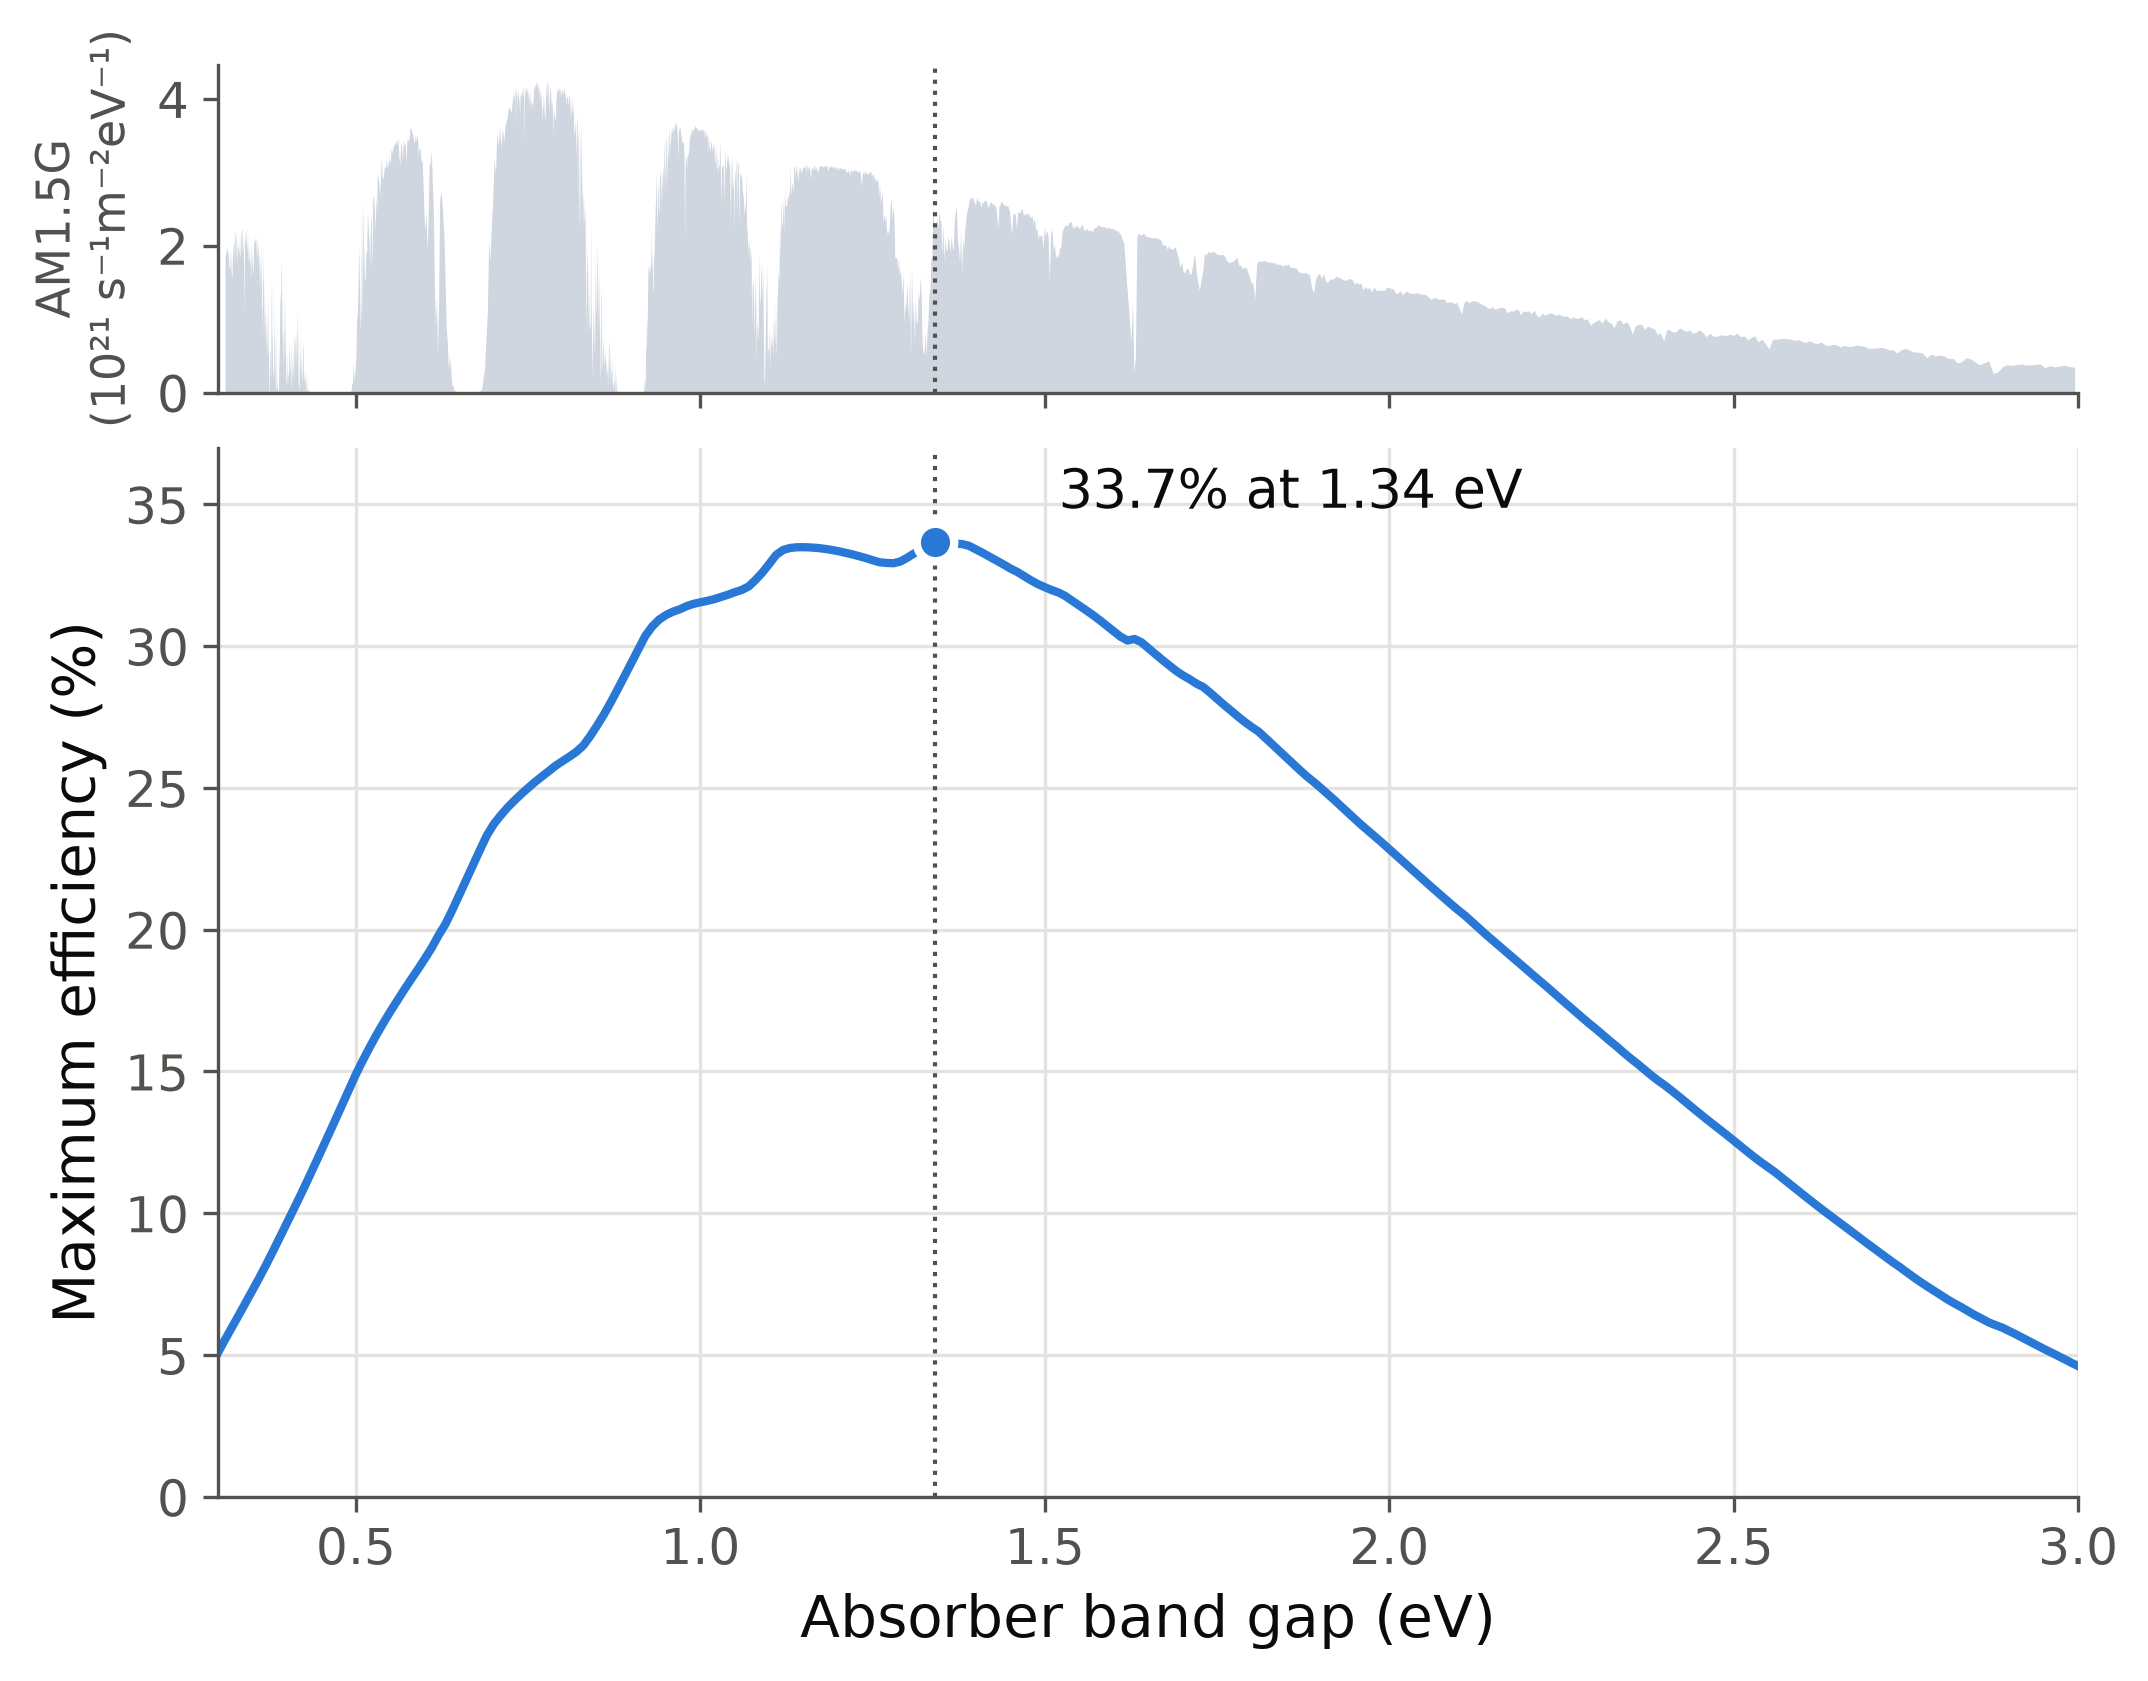

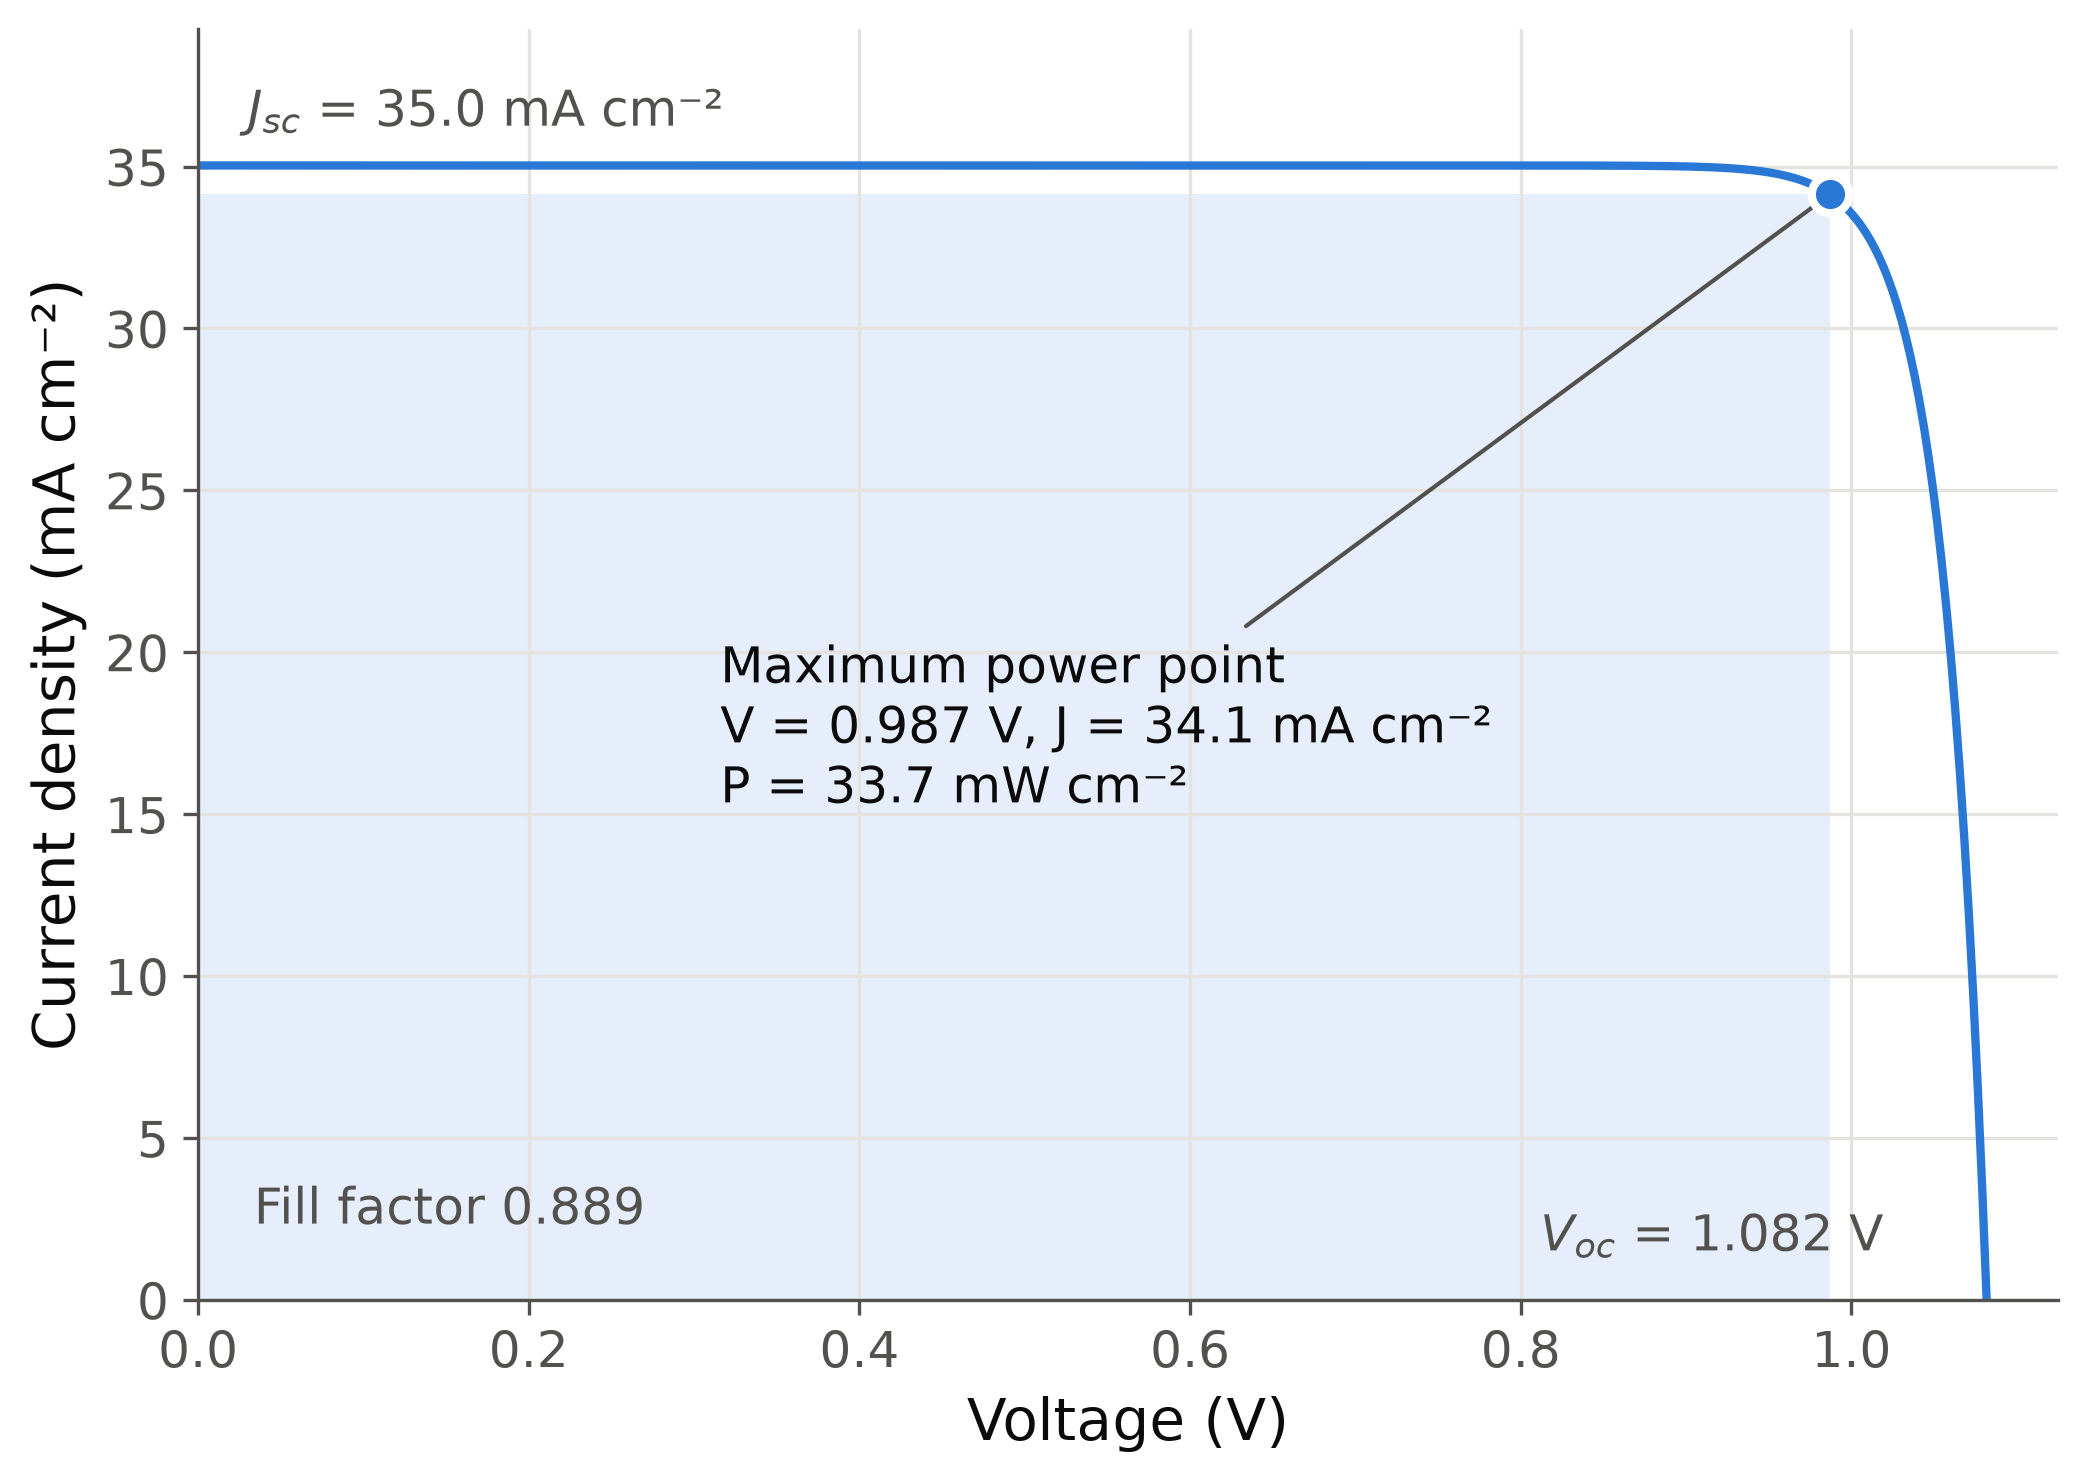

In [3]:
sq = pipeline.run_shockley_queisser()
print(f"Optimum gap        : {results_io.get_value('sq.optimum_gap_eV'):.2f} eV")
print(f"Maximum efficiency : {results_io.get_value('sq.optimum_efficiency_percent'):.2f} %")
print(f"Second peak        : {results_io.get_value('sq.secondary_peak')['gap_eV']:.2f} eV (water absorption band)")
show("fig01_sq_efficiency")
show("fig02_jv_curve", 640)

## Part 2 — What gap does a molecule actually have? HF vs DFT (Units I, IV)
Nine molecules: a thiophene ladder (1–3 rings), a phenyl ladder (1–2 rings), a donor–acceptor (push–pull) pair and
two dye cores. Each is built from SMILES, given a 3D shape by ETKDG, relaxed with the **MMFF94 force field**
(molecular mechanics), then optimised with **Hartree–Fock** and with **DFT (B3LYP)**, both in the 6-31G* basis.

**Predictions, written before looking at the numbers:**
1. **HF overestimates the gap badly**, by several eV. HF has no electron correlation, and its virtual (empty)
   orbitals, including the LUMO, are too high in energy.
2. **B3LYP is much closer** to experiment. (The brief expected it to *under*estimate the optical gap; we test
   this rather than assume it.)
3. **Longer conjugation → smaller gap**, as for a particle in a longer box: thiophene > bithiophene > terthiophene,
   and benzene > biphenyl.
4. In the push–pull molecule 4-nitroaniline, the **HOMO sits on the amino donor** and the **LUMO on the nitro
   acceptor**: light moves charge across the molecule.

[PASS] HF gap > B3LYP gap for every molecule: expected 9, got 9
[PASS] HF gap decreases monotonically along the thiophene ladder: expected decreasing, got [12.683, 10.513, 9.6]
[PASS] HF gap: biphenyl < benzene: expected biphenyl smaller, got [13.07, 11.334]
[PASS] B3LYP gap decreases monotonically along the thiophene ladder: expected decreasing, got [6.127, 4.339, 3.54]
[PASS] B3LYP gap: biphenyl < benzene: expected biphenyl smaller, got [6.797, 5.365]
[PASS] B3LYP is closer to the experimental optical gap than HF: expected 2, got 2
[PASS] HF overestimates the experimental optical gap by more than 1 eV: expected 2, got 2
[PASS] benzene: B3LYP/6-31G* gap within 0.3 eV of QM9 B3LYP/6-31G(2df,p): expected 6.811, got 6.797
[PASS] 4-aminobenzonitrile: B3LYP/6-31G* gap within 0.3 eV of QM9 B3LYP/6-31G(2df,p): expected 5.208, got 5.178
[PASS] MMFF94 optimisation lowered the force-field energy of every molecule: expected 9, got 9
[PASS] 4-nitroaniline: LUMO density sits nearer the acceptor th

molecule                 HF gap  B3LYP gap  HF-B3LYP   expt  B3LYP time
benzene                   13.07       6.80      6.27      -         30s
biphenyl                  11.33       5.37      5.97      -        441s
thiophene                 12.68       6.13      6.56   5.37         50s
bithiophene               10.51       4.34      6.17   4.09        389s
terthiophene               9.60       3.54      6.06      -       2465s
4-nitroaniline            10.90       4.30      6.60      -        346s
4-aminobenzonitrile       11.48       5.18      6.30      -        196s
coumarin                  10.76       4.62      6.15      -        310s
azobenzene                10.04       3.93      6.11      -       1555s


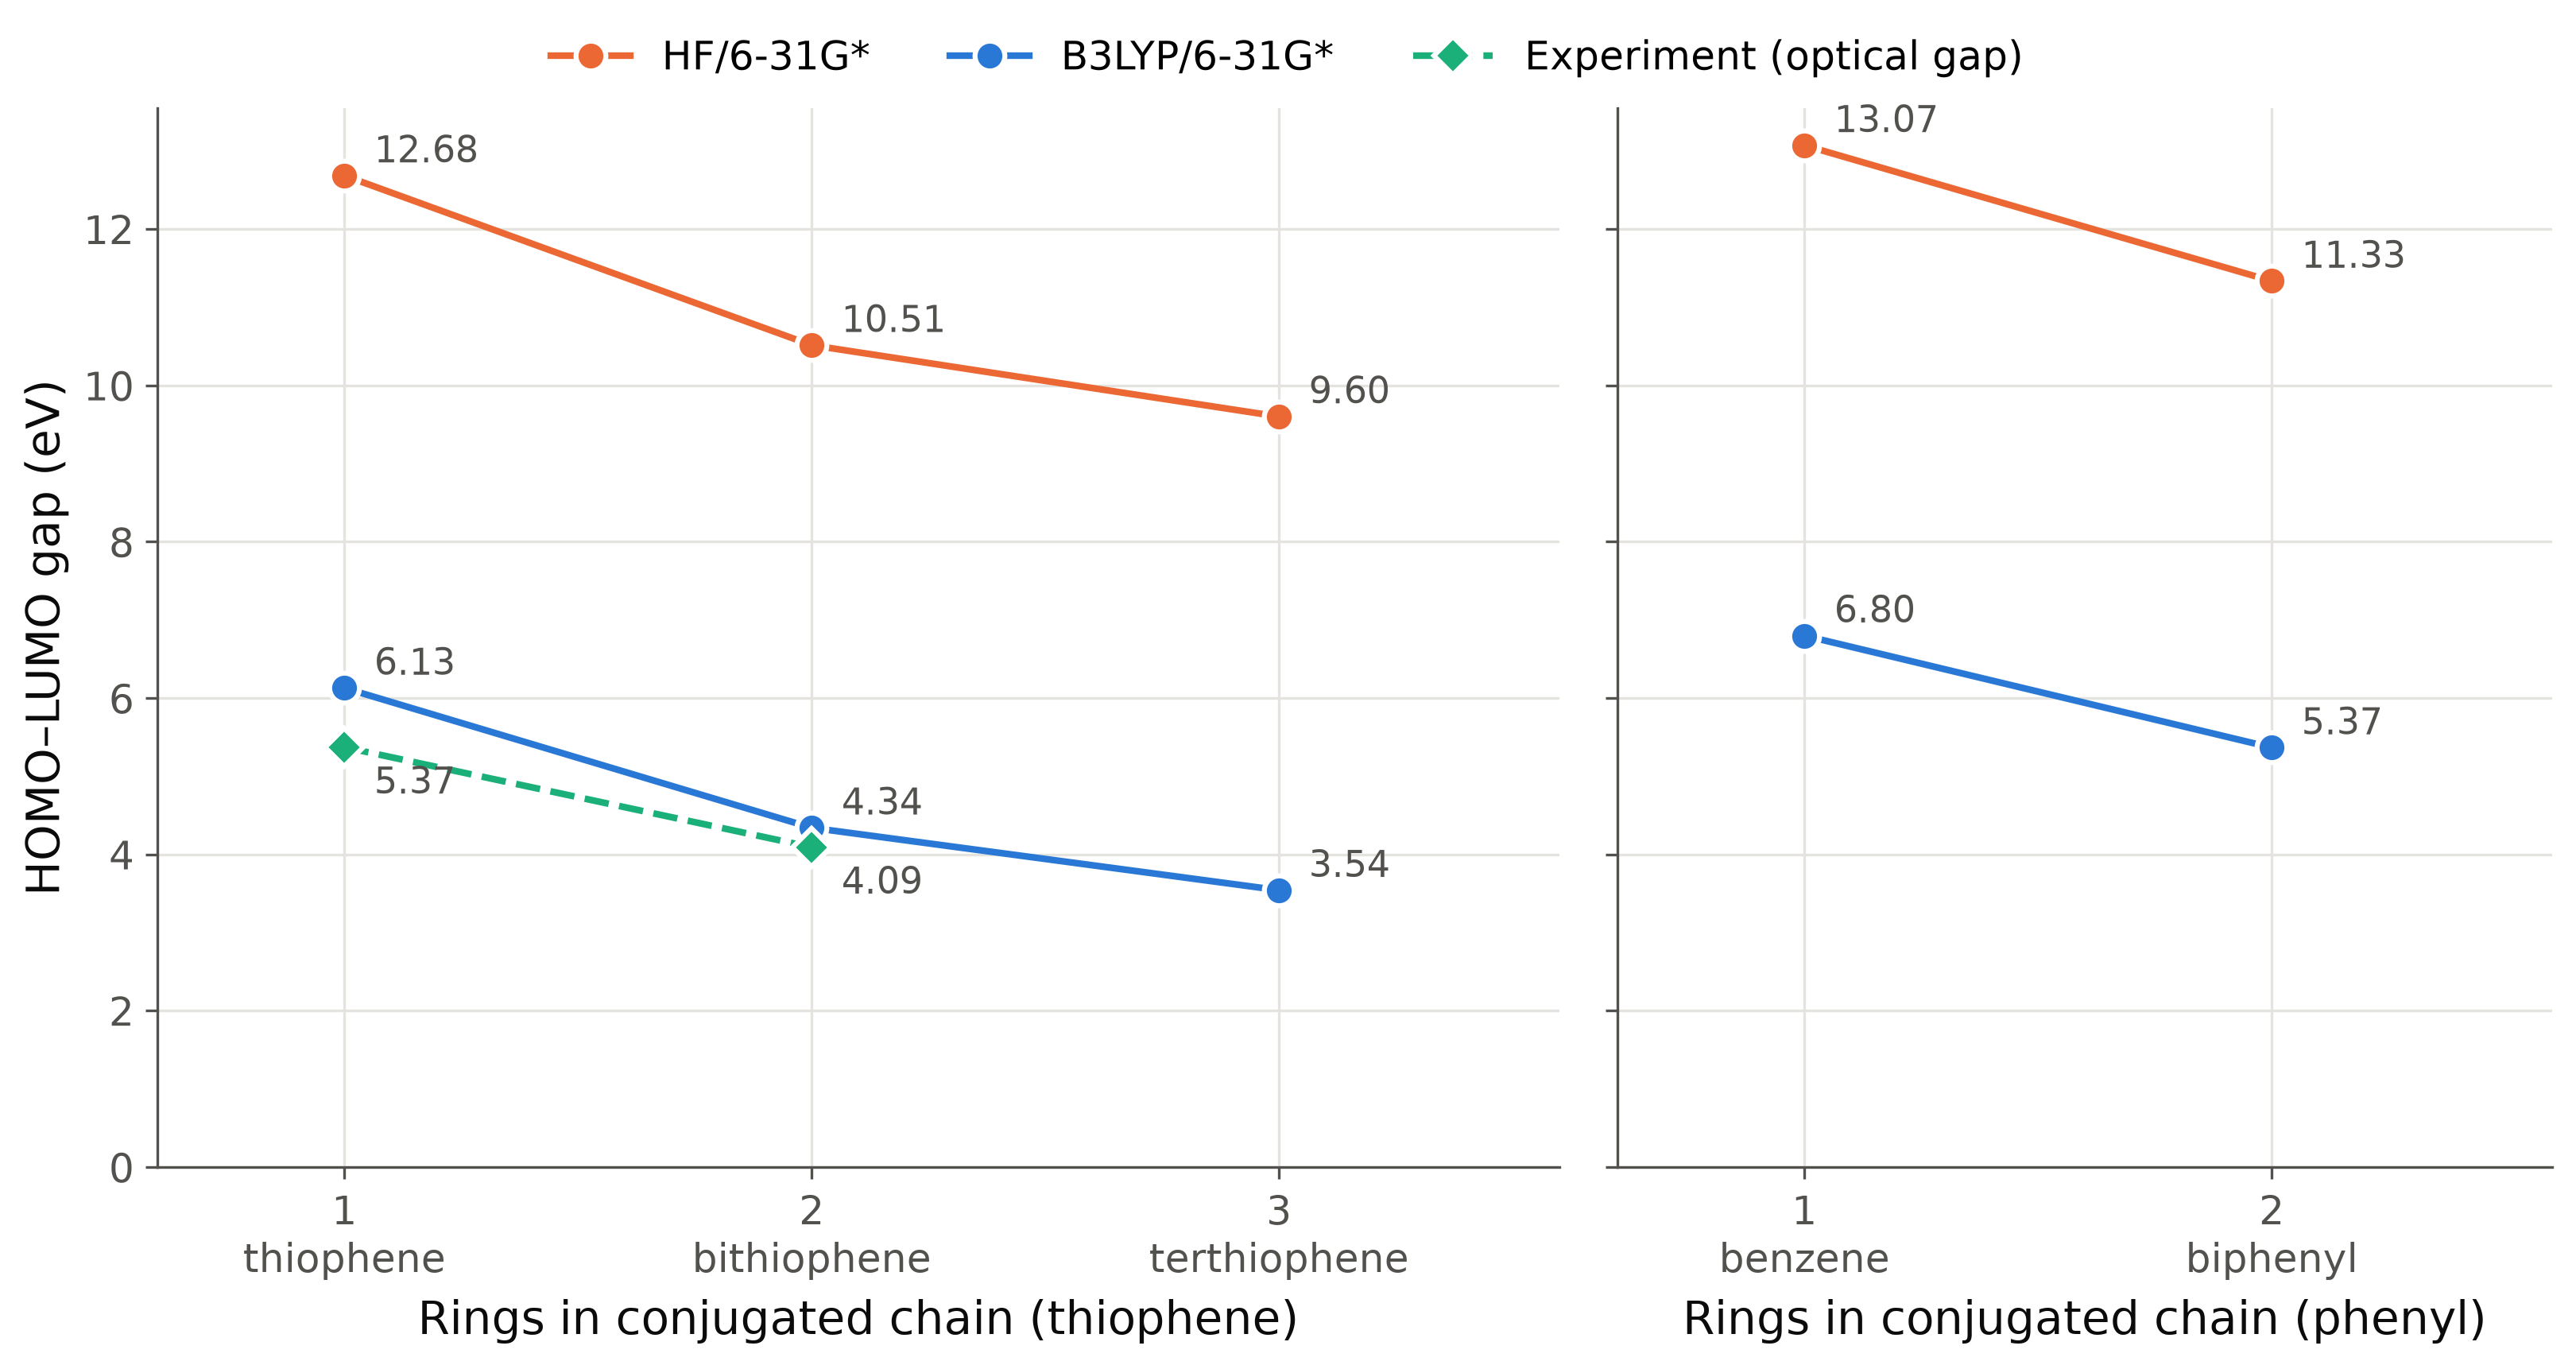

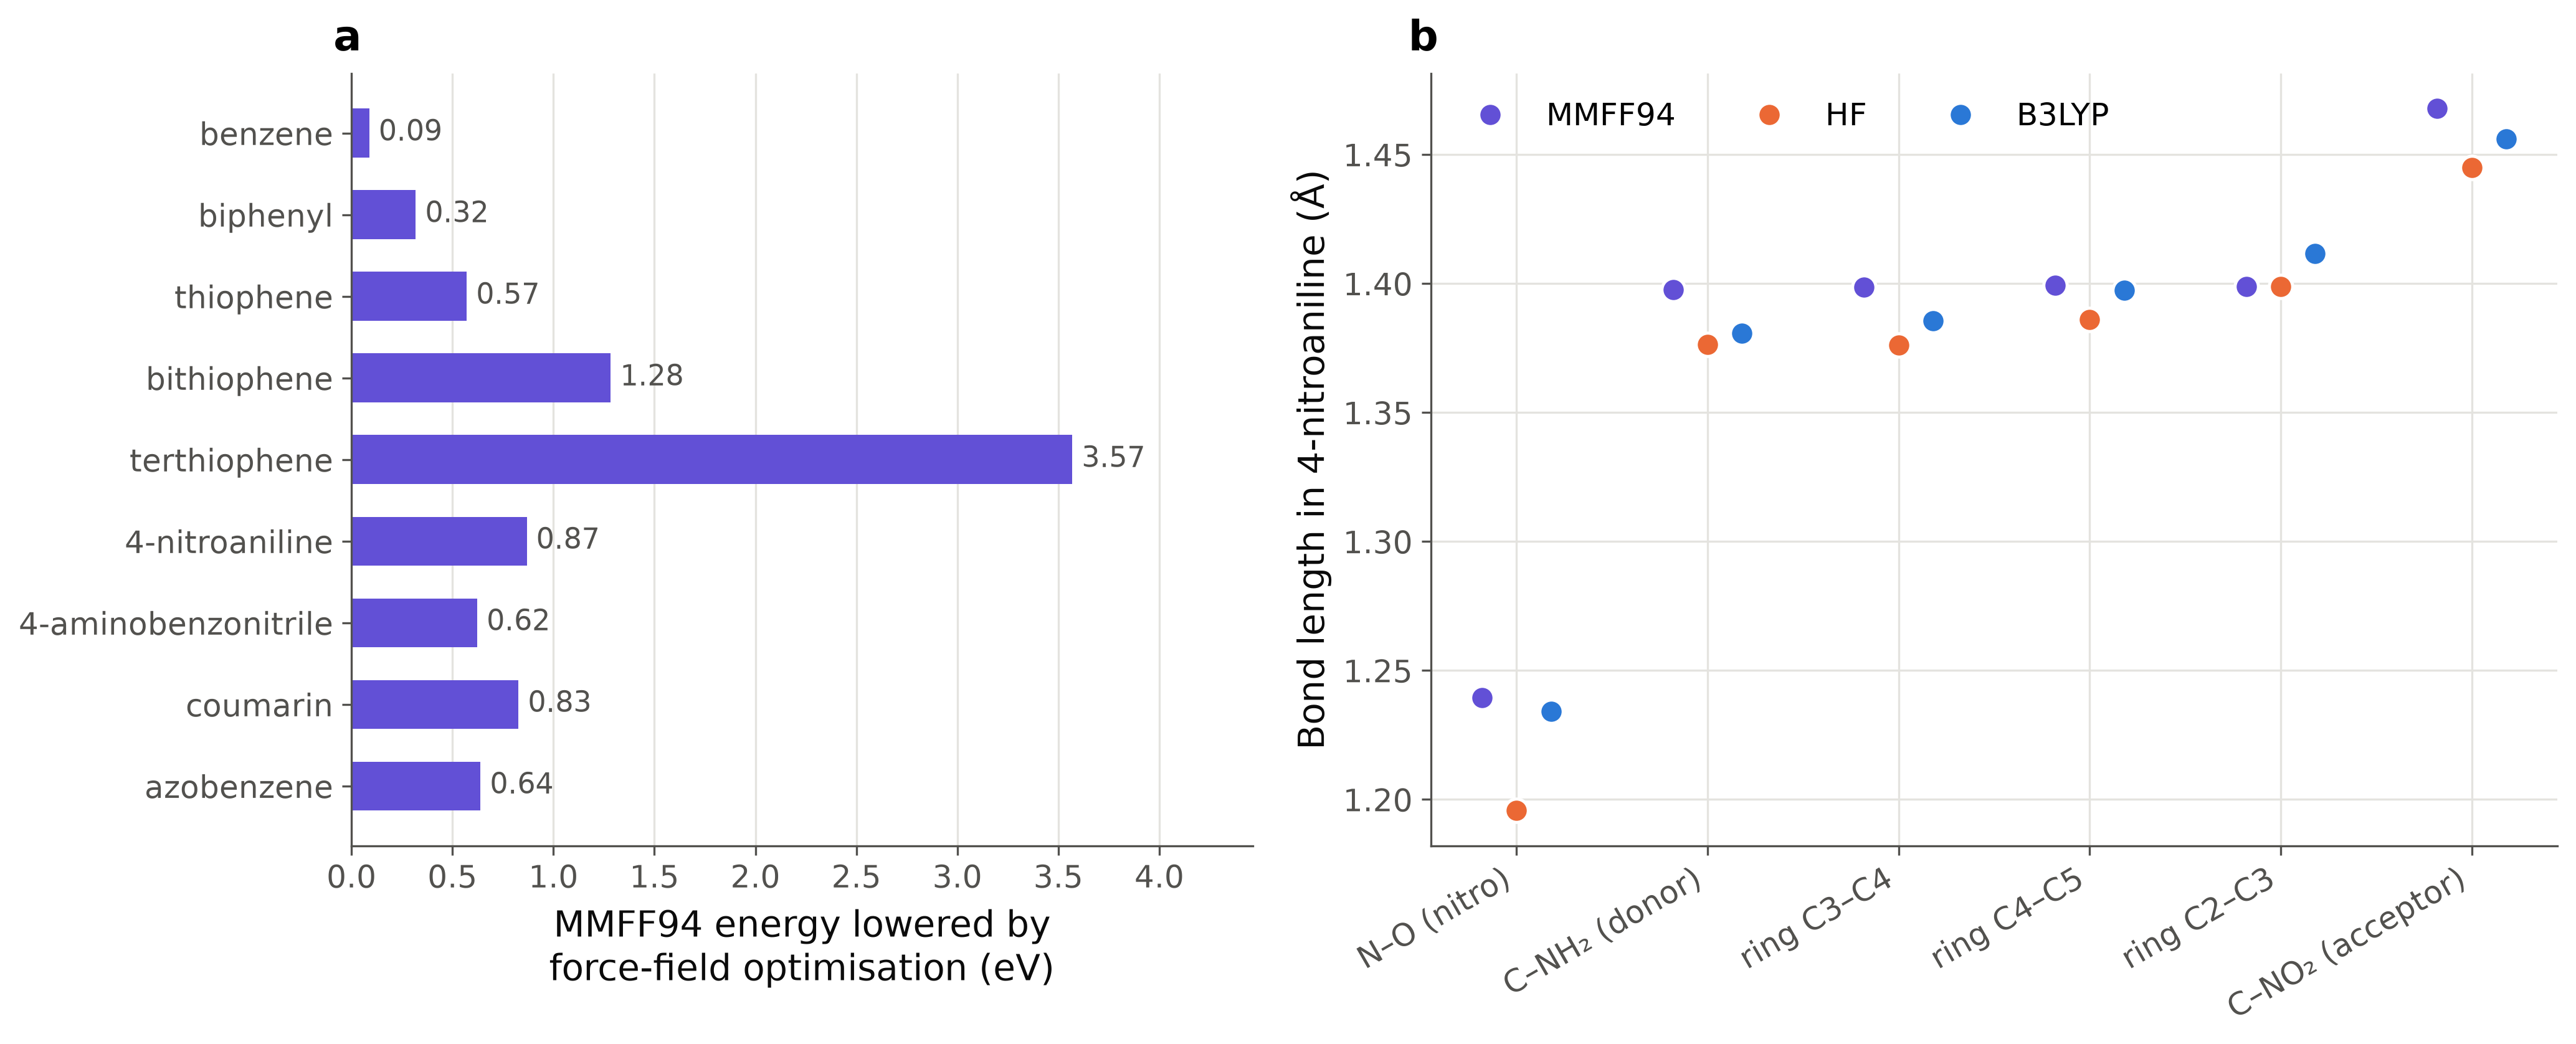

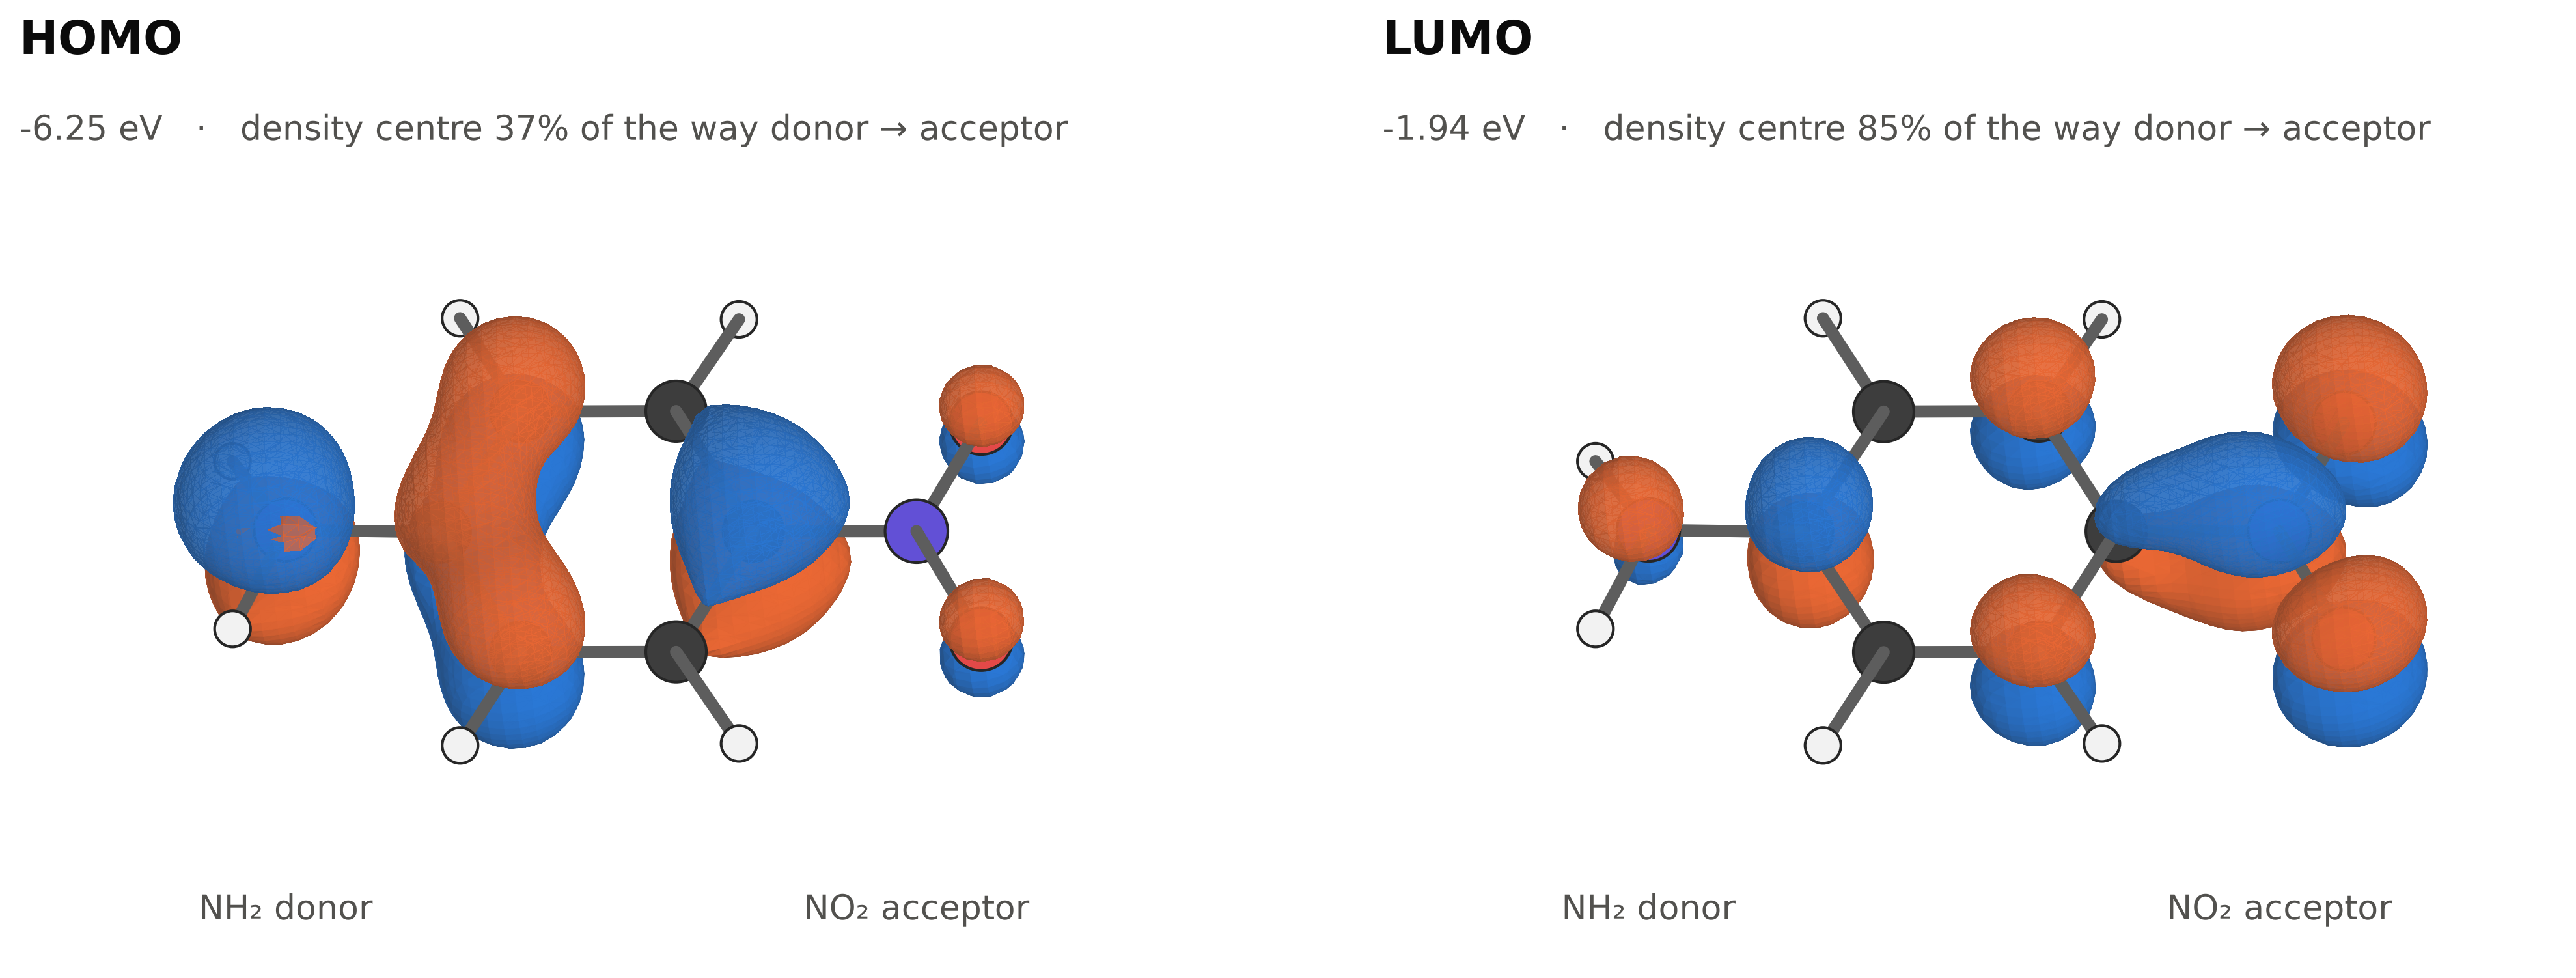

{
 "donor_atom_index": 0,
 "acceptor_atom_index": 7,
 "donor_acceptor_distance_A": 5.6288729599983895,
 "homo_centroid_fraction": 0.371486310092971,
 "lumo_centroid_fraction": 0.848422074385787,
 "charge_transfer_shift_A": 2.6846108272839975,
 "cube_files": [
  "cache\\quantum\\4-nitroaniline__B3LYP__HOMO.cube",
  "cache\\quantum\\4-nitroaniline__B3LYP__LUMO.cube"
 ]
}


In [4]:
molecules = pipeline.run_quantum_molecules()
print(f"{'molecule':<22}{'HF gap':>9}{'B3LYP gap':>11}{'HF-B3LYP':>10}{'expt':>7}{'B3LYP time':>12}")
for m in molecules:
    expt = m['reference'].get('experimental_optical_gap', {}).get('gap_eV')
    expt_text = f"{expt:.2f}" if expt is not None else "  -"
    print(f"{m['name']:<22}{m['HF']['gap_eV']:9.2f}{m['B3LYP']['gap_eV']:11.2f}"
          f"{m['gap_difference_HF_minus_B3LYP_eV']:10.2f}{expt_text:>7}{m['B3LYP']['wall_seconds']:11.0f}s")
show("fig03_gap_vs_conjugation")
show("fig04_mmff_vs_quantum", 900)
show("fig05_orbitals", 900)
print(json.dumps(results_io.get_value("quantum.push_pull")["4-nitroaniline"], indent=1))

## Part 3 — A potential energy surface: torsion controls the gap (Units I, IV)
Bithiophene can twist about the bond joining its rings. We fix the S–C–C–S dihedral at 0°, 10°, … 180°, relax
everything else at B3LYP/6-31G*, and record energy and gap at each angle.

**Prediction:** the **energy minimum is twisted** (steric repulsion between the rings beats the extra
π-conjugation of the flat form), but the **gap is smallest when the molecule is planar**, because that is when
the two rings' π orbitals overlap best. The shape the molecule prefers is not its best optical shape.

bithiophene B3LYP: loaded from cache
[PASS] torsion PES minimum is not at exactly 0 or 180 deg: expected not 0/180, got 160.0
[PASS] gap at planarity is the minimum of the gap scan: expected 0 or 180 deg, got 0.0
[PASS] gap is largest near perpendicular (60-120 deg): expected 60-120 deg, got 90.0
[PASS] every constrained dihedral reached its target within 1 deg: expected <= 1 deg, got 0.0
[PASS] torsion scan covers 0-180 deg in 10 deg steps: expected 19, got 19
[PASS] inter-ring C-C bond is longest at perpendicular (conjugation broken): expected 90.0, got 90.0


[PASS] Part 2 free-optimised bithiophene dihedral within 15 deg of the scan minimum: expected 160.0, got 159.1


Energy minimum at         : 160 deg
Cost of flattening        : 3.9 meV (to 180 deg)
Barrier at                : 90 deg, 117.5 meV
Gap range over the scan   : 4.22 - 5.82 eV


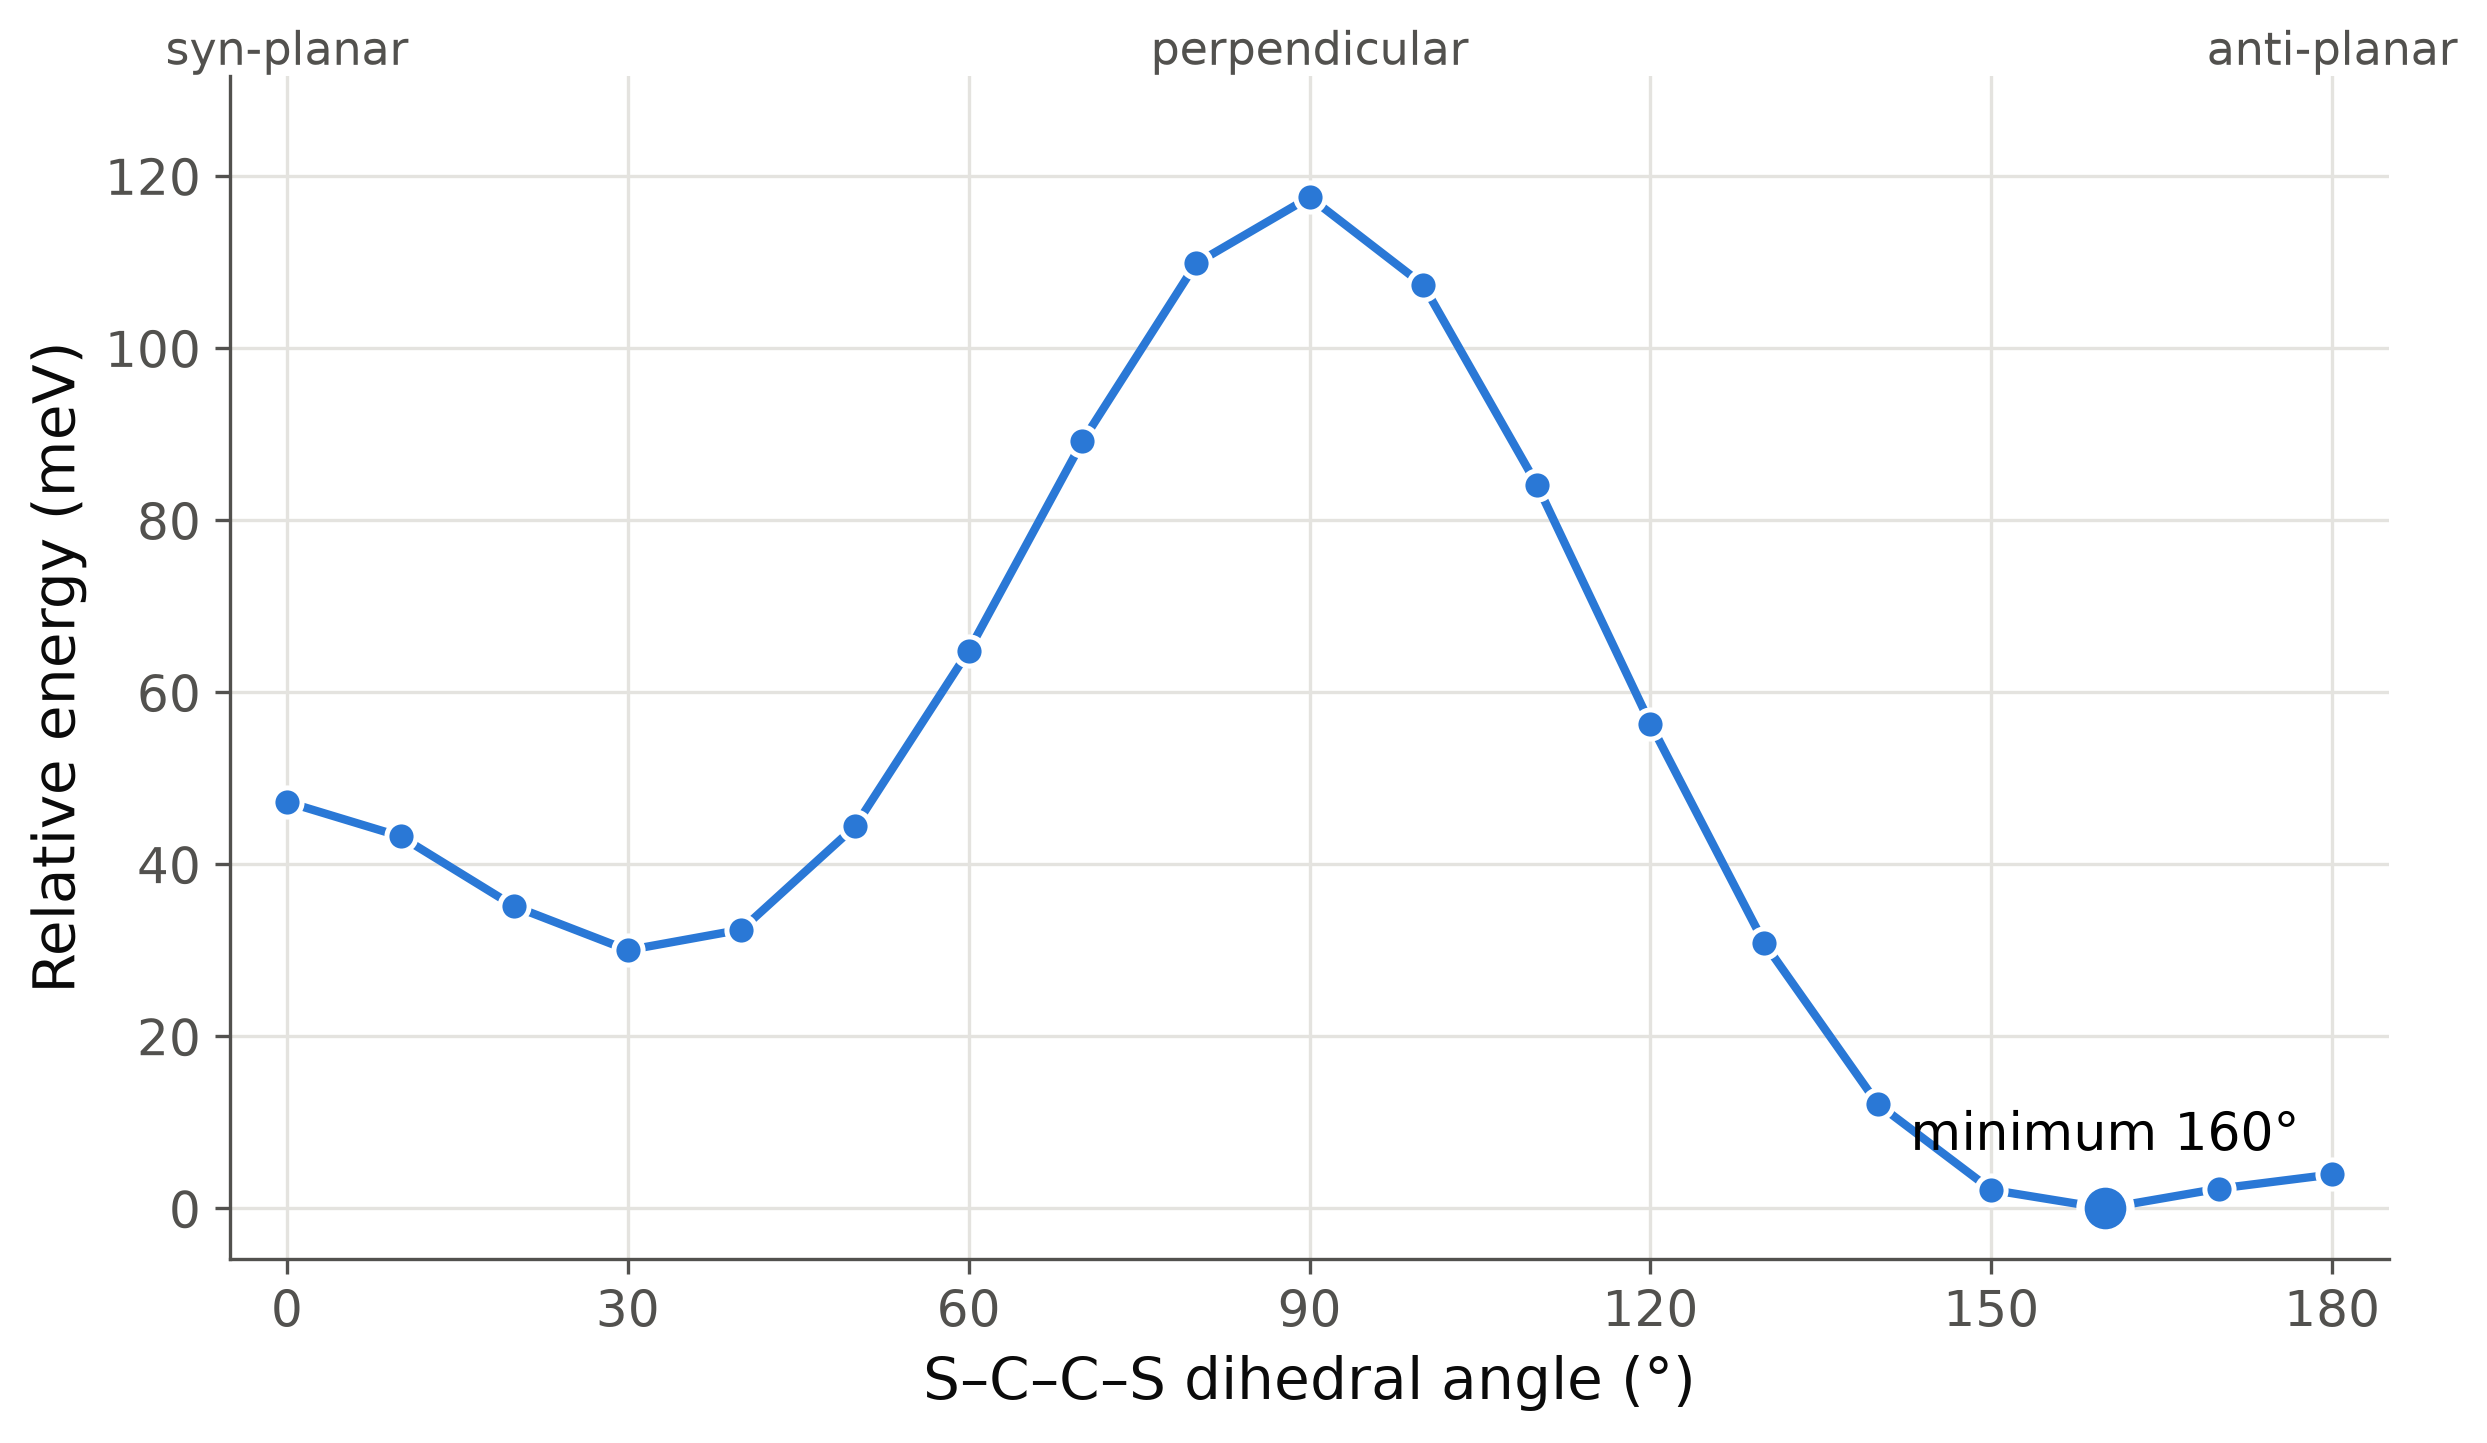

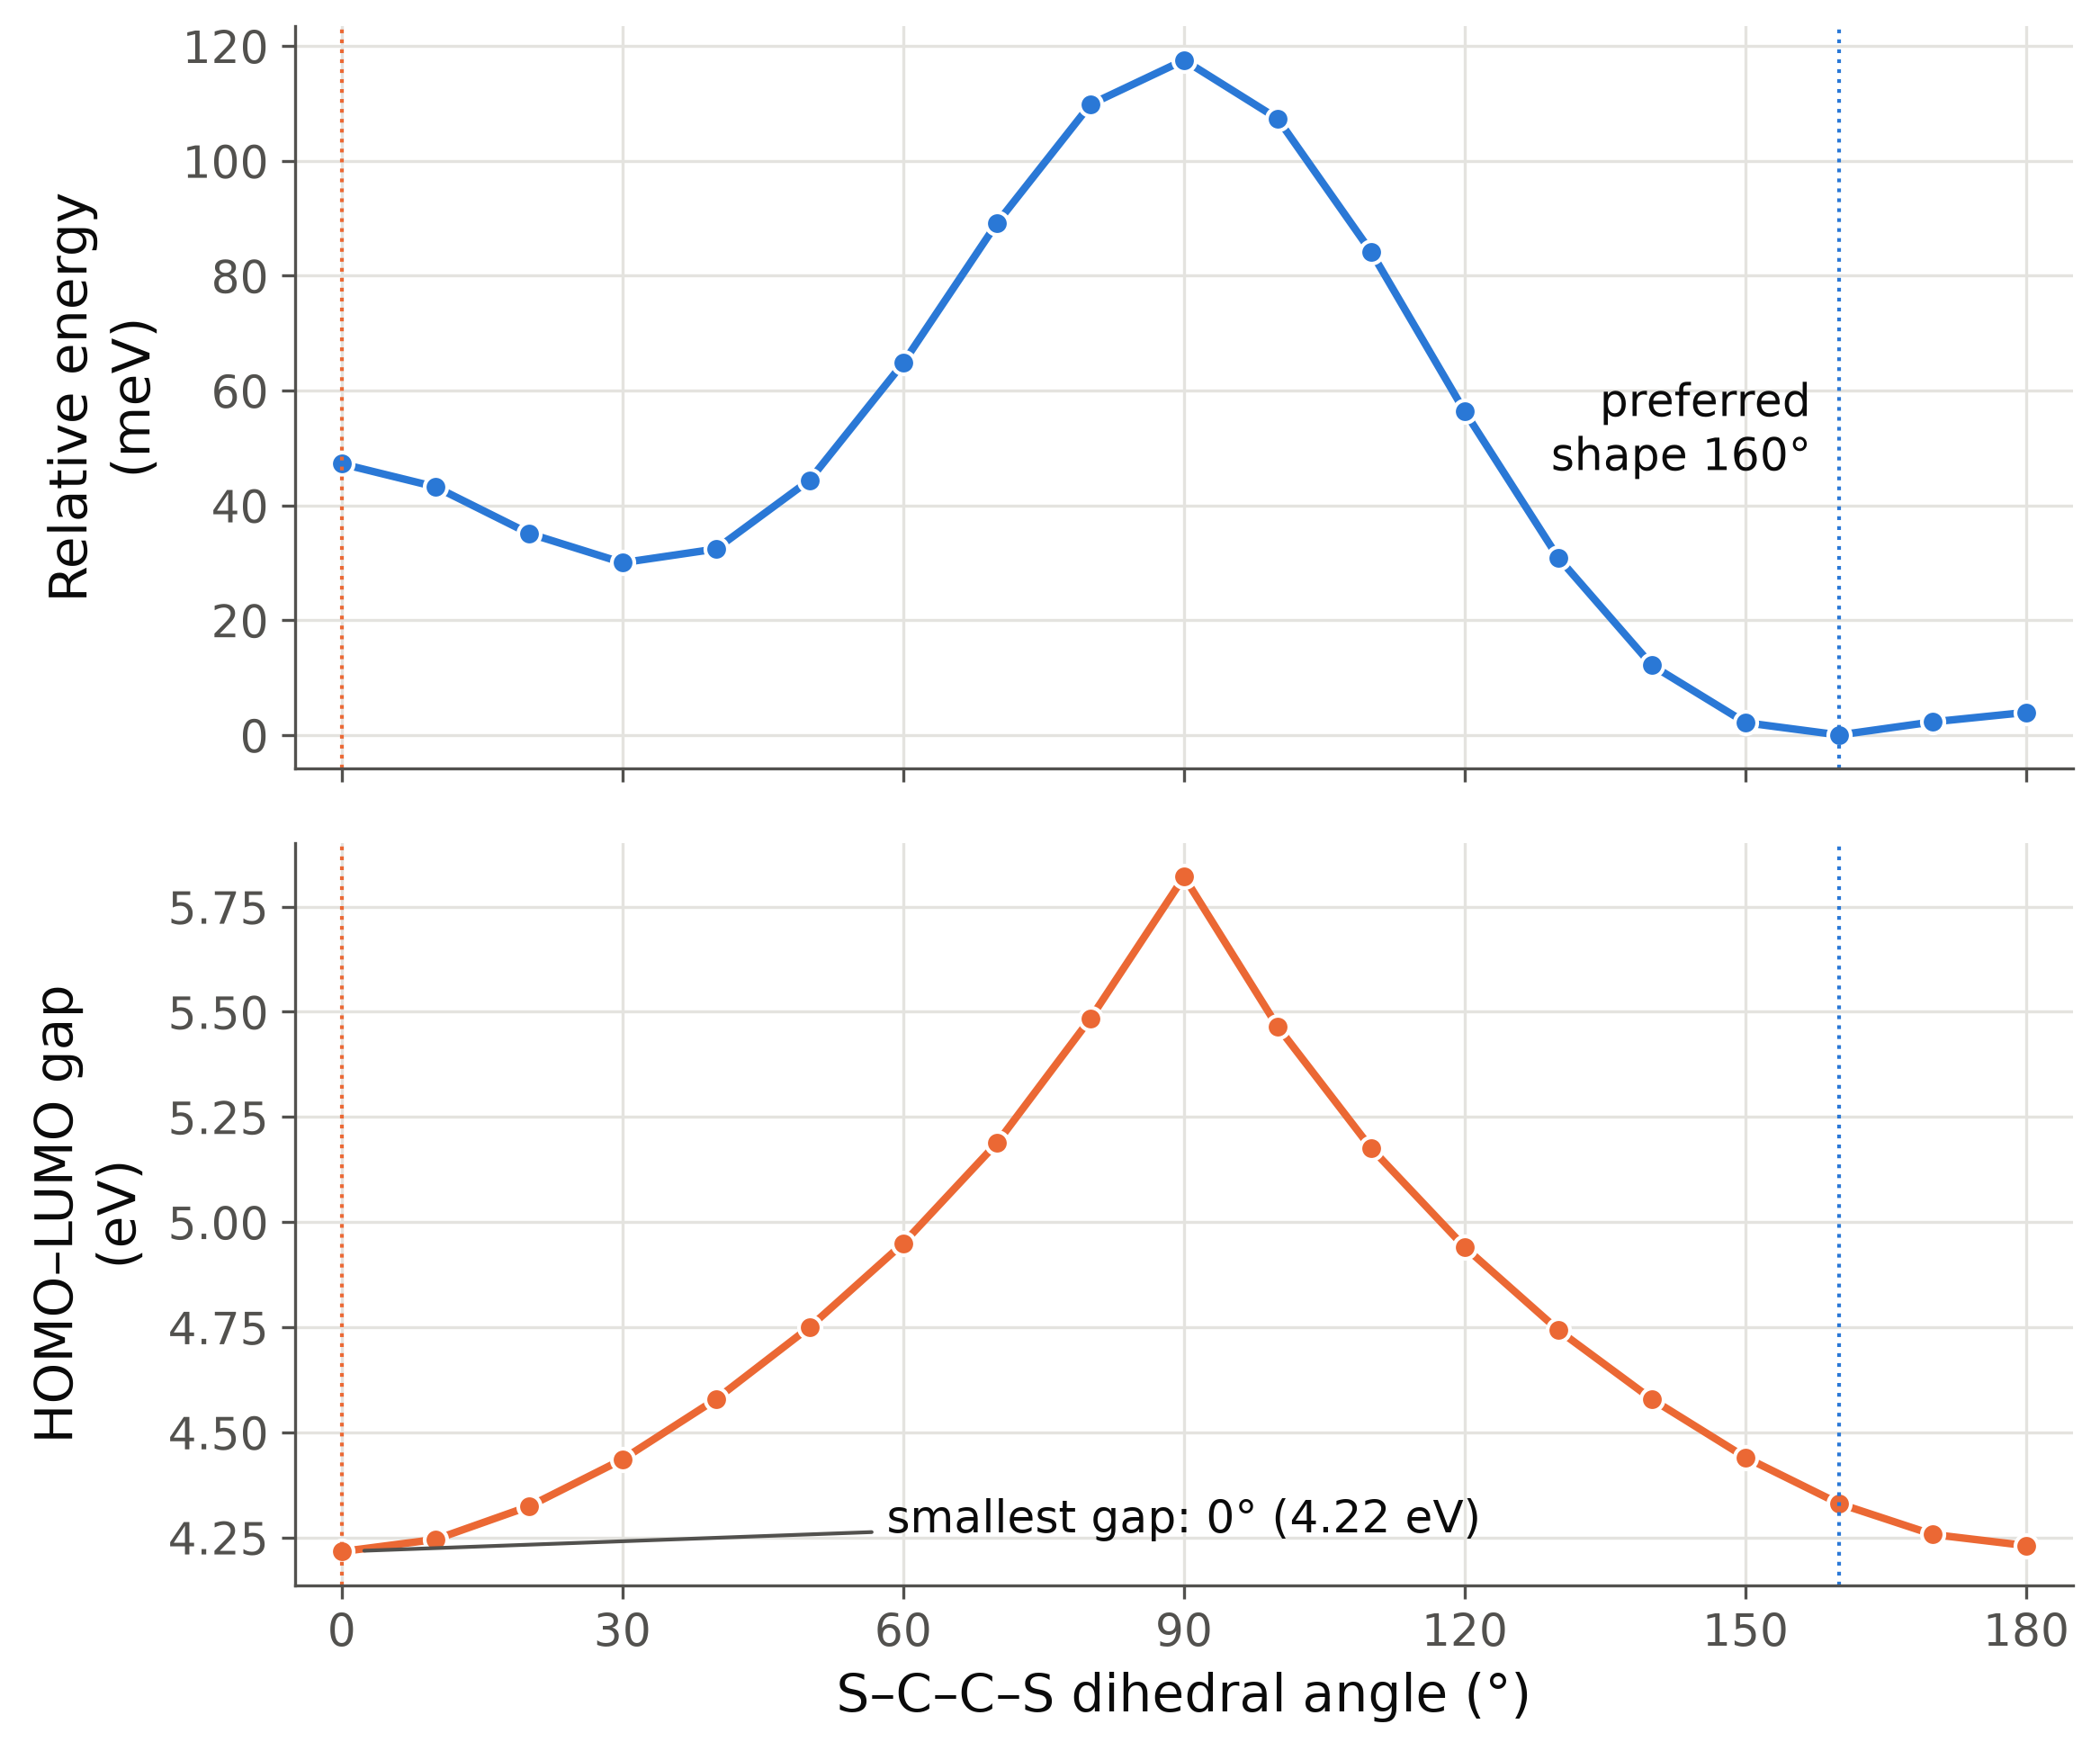

In [5]:
points, summary = pipeline.run_torsion()
print(f"Energy minimum at         : {summary['minimum_angle_deg']:.0f} deg")
print(f"Cost of flattening        : {summary['barrier_to_planarity_eV'] * 1000:.1f} meV "
      f"(to {summary['best_planar_angle_deg']:.0f} deg)")
print(f"Barrier at                : {summary['rotational_barrier_angle_deg']:.0f} deg, "
      f"{summary['rotational_barrier_eV'] * 1000:.1f} meV")
print(f"Gap range over the scan   : {summary['gap_range_eV'][0]:.2f} - {summary['gap_range_eV'][1]:.2f} eV")
show("fig06_torsion_pes", 680)
show("fig07_torsion_gap", 680)

## Part 4 — Describing molecules with numbers; drug-likeness vs dye-likeness (Unit II)
Eleven descriptors for every QM9 molecule: ten from RDKit, plus a **conjugation proxy written by hand**: the size of
the largest connected π system. That is aromatic atoms, atoms with a double or triple bond, and N/O/S lone pairs
sitting next to them, grouped into connected pieces (see `largest_conjugated_system` in `src/descriptors.py`).

**Lipinski's Rule of Five** (MW ≤ 500, LogP ≤ 5, H-bond donors ≤ 5, acceptors ≤ 10; at most one violation) predicts
whether a *drug* is absorbed from the gut. A solar dye never has to cross a gut wall, so we expect Lipinski to say
nothing useful here. As a counterpart we define a **dye-likeness filter: our own construction by analogy, not a
literature standard**. It asks for extended conjugation, a mostly conjugated (planarity-capable) skeleton, a donor *and*
an acceptor group, no thermally weak bonds, and no charge-separated (zwitterionic) structures.

**Predictions:** almost every small QM9 molecule passes Lipinski, while few pass the dye filter; for real
photovoltaic molecules (HOPV15) it is the other way round. The conjugation proxy should be the descriptor most
strongly (and negatively) correlated with the gap.

[PASS] hand-written conjugation proxy matches hand-counted examples: expected {'CC': 0, 'C=C': 2, 'C=CC=C': 4, 'c1ccccc1': 6, 'Nc1ccccc1': 7, 'c1ccc(-c2ccccc2)cc1': 12, 'C=CCC=C': 2}, got {'CC': 0, 'C=C': 2, 'C=CC=C': 4, 'c1ccccc1': 6, 'Nc1ccccc1': 7, 'c1ccc(-c2ccccc2)cc1': 12, 'C=CCC=C': 2}
[PASS] descriptors computed for every cleaned QM9 and HOPV15 molecule: expected [130831, 350], got [130831, 350]
[PASS] larger conjugated system correlates with a smaller gap (Pearson r < 0): expected < 0, got -0.721
[PASS] dye filter accepts 4-nitroaniline and rejects benzene: expected [True, False], got [True, False]


            Lipinski pass  dye filter pass
QM9               100.0%           10.0%
HOPV               26.9%           86.6%

Dye-filter rules passed (QM9): {'extended_conjugation': 21654, 'planarity_capable': 31619, 'donor_and_acceptor': 27045, 'thermal_stability_proxy': 50339, 'no_charge_separation': 130388}

Pearson correlation with the gap:
  Largest conjugated system (atoms)   -0.721
  Bertz complexity                    -0.510
  TPSA (Å²)                           -0.413
  Aromatic rings                      -0.403
  H-bond acceptors                    -0.376
  H-bond donors                       -0.105
  Molecular weight (g/mol)            -0.007
  Rotatable bonds                     +0.055
  Rings                               +0.239
  LogP (Crippen)                      +0.307
  Fraction sp³ carbons                +0.712


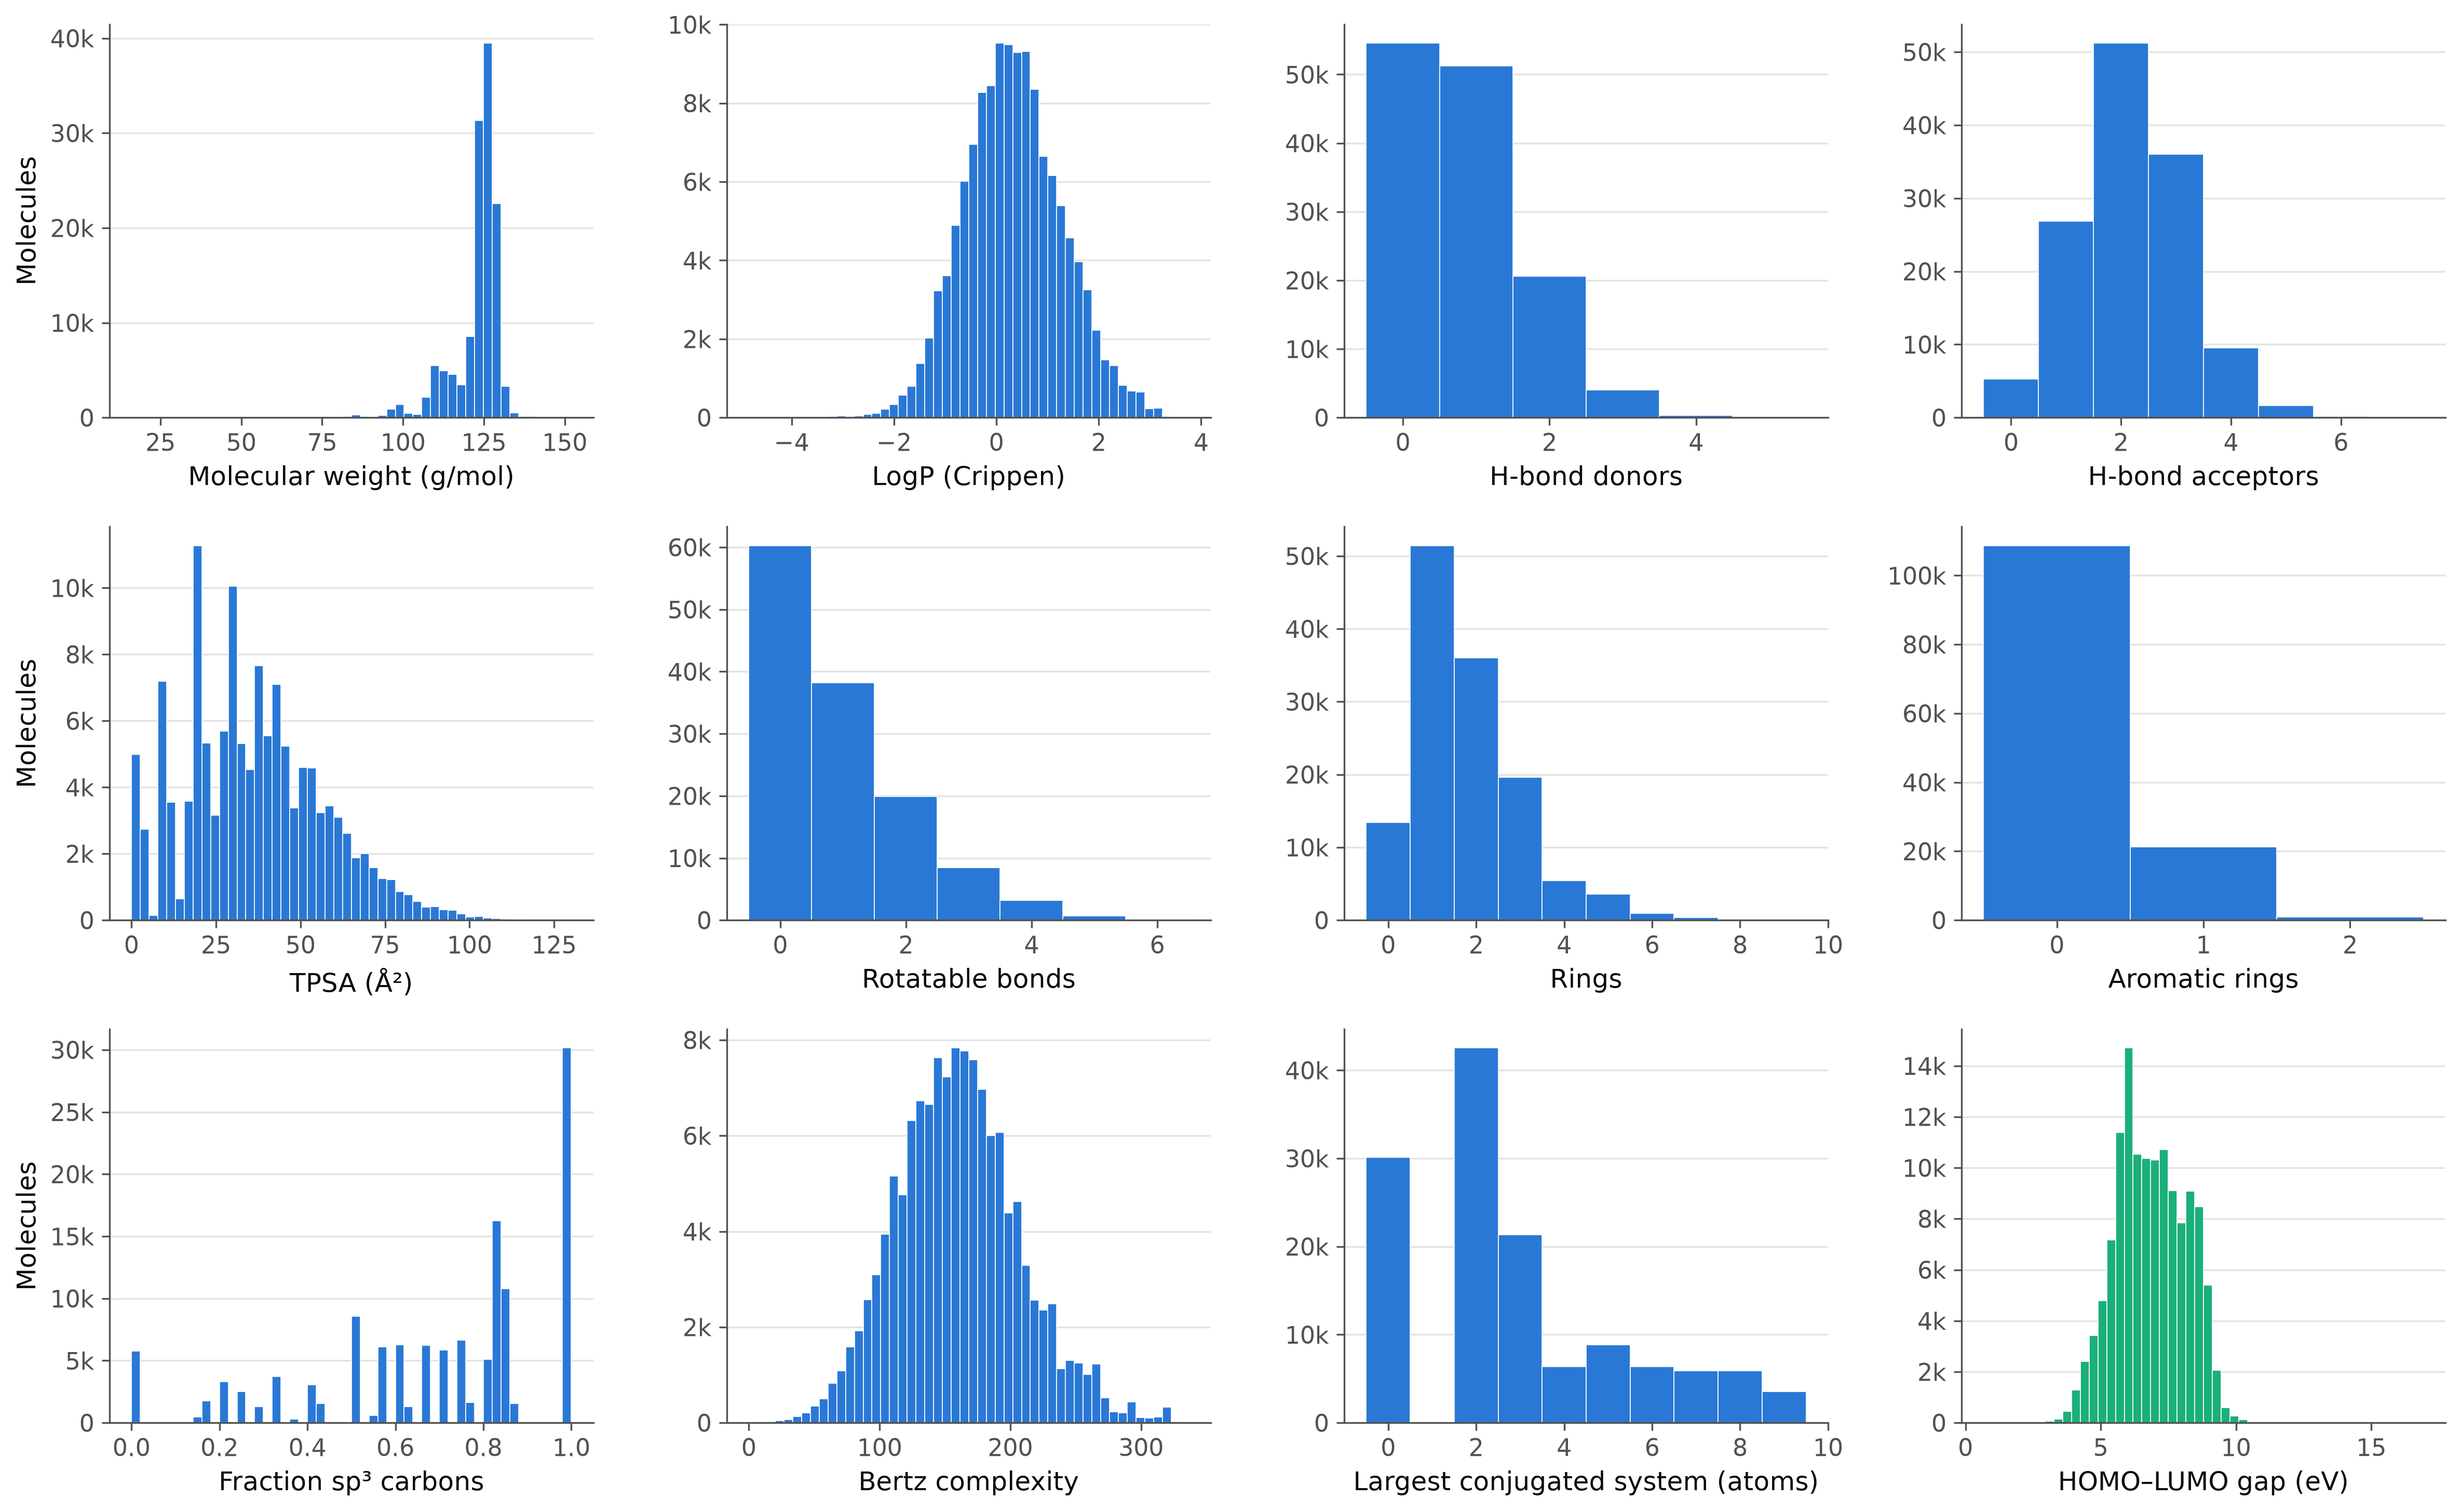

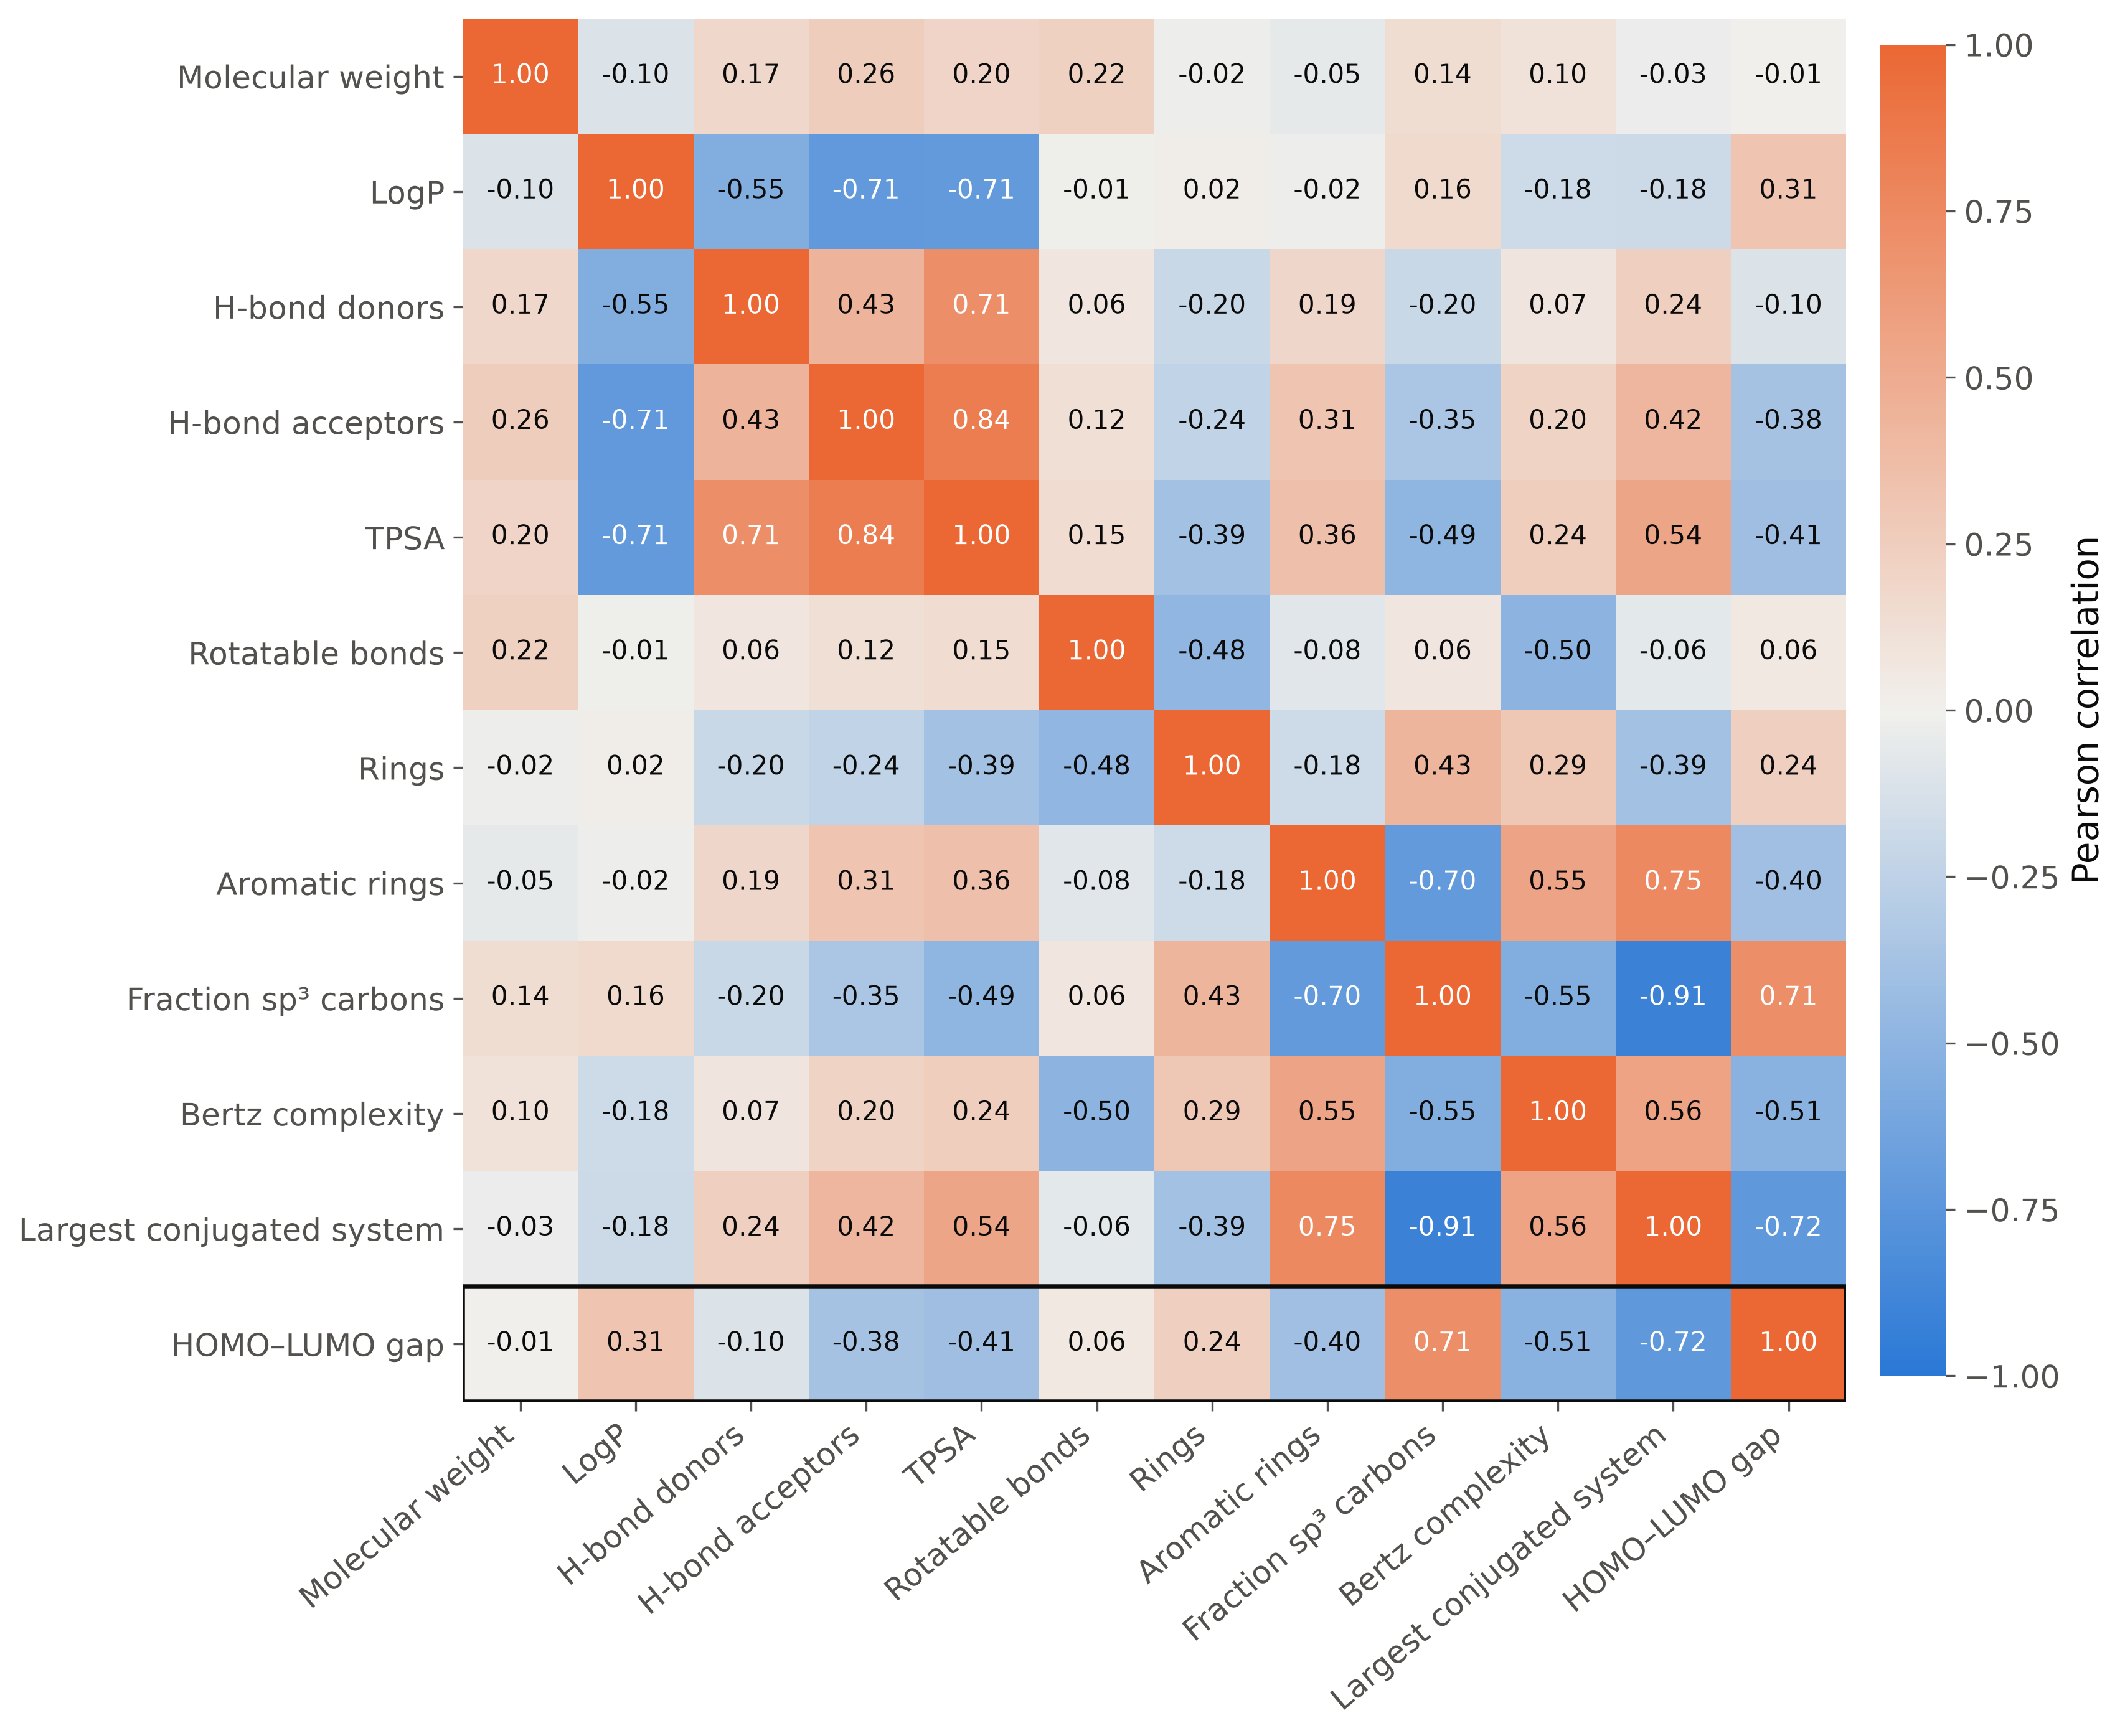

In [6]:
qm9_table, hopv_table = pipeline.run_descriptors()
d = results_io.get_value("descriptors")
print(f"{'':<10}{'Lipinski pass':>15}{'dye filter pass':>17}")
for name in ("qm9", "hopv"):
    print(f"{name.upper():<10}{d[name]['lipinski_pass_rate']:>14.1%}{d[name]['dye_filter_pass_rate']:>16.1%}")
print()
print("Dye-filter rules passed (QM9):", d["qm9"]["dye_rule_pass_counts"])
print()
print("Pearson correlation with the gap:")
for name, value in sorted(d["correlations_with_gap"].items(), key=lambda item: item[1]["pearson"]):
    print(f"  {d['labels'][name]:<36}{value['pearson']:+.3f}")
show("fig09_descriptor_distributions", 900)
show("fig10_correlation_heatmap", 760)

## Part 5 — A machine-learning surrogate, and the screen it makes possible (Unit II)
Three models learn the QM9 B3LYP gap from the eleven descriptors: **ridge regression** (linear, interpretable),
**random forest** and **gradient boosting** (both built from decision trees). The split is **random 80/10/10**
(justified in `src/model.py`), the features are standardised with the population standard deviation (`ddof=0`)
fitted on the training rows only, hyperparameters are chosen on the validation set, and the test set is used once.

**Predictions:** ridge reaches only a modest R², because the gap is not a straight-line function of these
descriptors; the tree models do much better. Even so, any descriptor model has a ceiling: it never sees the 3D
geometry or the electrons, so two isomers with identical descriptors get identical predictions.

**The payoff:** the trained model ranks every dye-filter-passing QM9 molecule by how close its predicted gap is to
the Shockley–Queisser optimum, and the top 3 are re-calculated with real B3LYP/6-31G* (the Part 2 protocol).

**Out-of-domain test:** the model is also asked about HOPV15, which holds real photovoltaic molecules several times
larger than anything in QM9, and compared with HOPV15's own B3LYP gaps.

models: loaded from cache


[PASS] train/validation/test split is disjoint and covers every QM9 row: expected 130831, got 130831
[PASS] standardised training features have mean 0 and std 1 (ddof=0): expected < 1e-9, got 1.401897108248556e-12
[PASS] both tree models beat the ridge baseline on test MAE: expected trees < ridge, got {'ridge': 0.6032, 'random_forest': 0.228, 'gradient_boosting': 0.2259}
[PASS] every top candidate passes the dye-likeness filter: expected 10, got 10
[PASS] top 3 candidates have a real B3LYP gap: expected 3, got 3


model                 test MAE  test RMSE  test R2   hyperparameters
ridge                   0.603      0.750    0.657   {'alpha': 0.001}
random_forest           0.228      0.314    0.940   {'min_samples_leaf': 1, 'max_features': 0.5}
gradient_boosting       0.226      0.308    0.942   {'learning_rate': 0.1, 'max_leaf_nodes': 127}
best model (by validation MAE): gradient_boosting

rank SMILES                     predicted  QM9 DFT  our B3LYP  split
1    CCNC(=N)C(=O)C=O                3.10     3.03       2.99  train
2    C(=O)C(=O)C(=N)NC=N             3.31     3.15       2.96  train
3    c1coc2c1C(=O)C=C2               3.55     3.42       3.38  train
4    c1coc2c1C=CC2=O                 3.55     3.55          -  train
5    CCN=C(C(=O)C=O)N                3.59     3.75          -  train
6    c1c[nH]c2c1C(=O)C=C2            3.59     3.42          -  train
7    c1c[nH]c2c1C=CC2=O              3.59     3.50          -  train
8    C1C(=O)C(=O)C(=N1)N             3.61     3.22          -  t

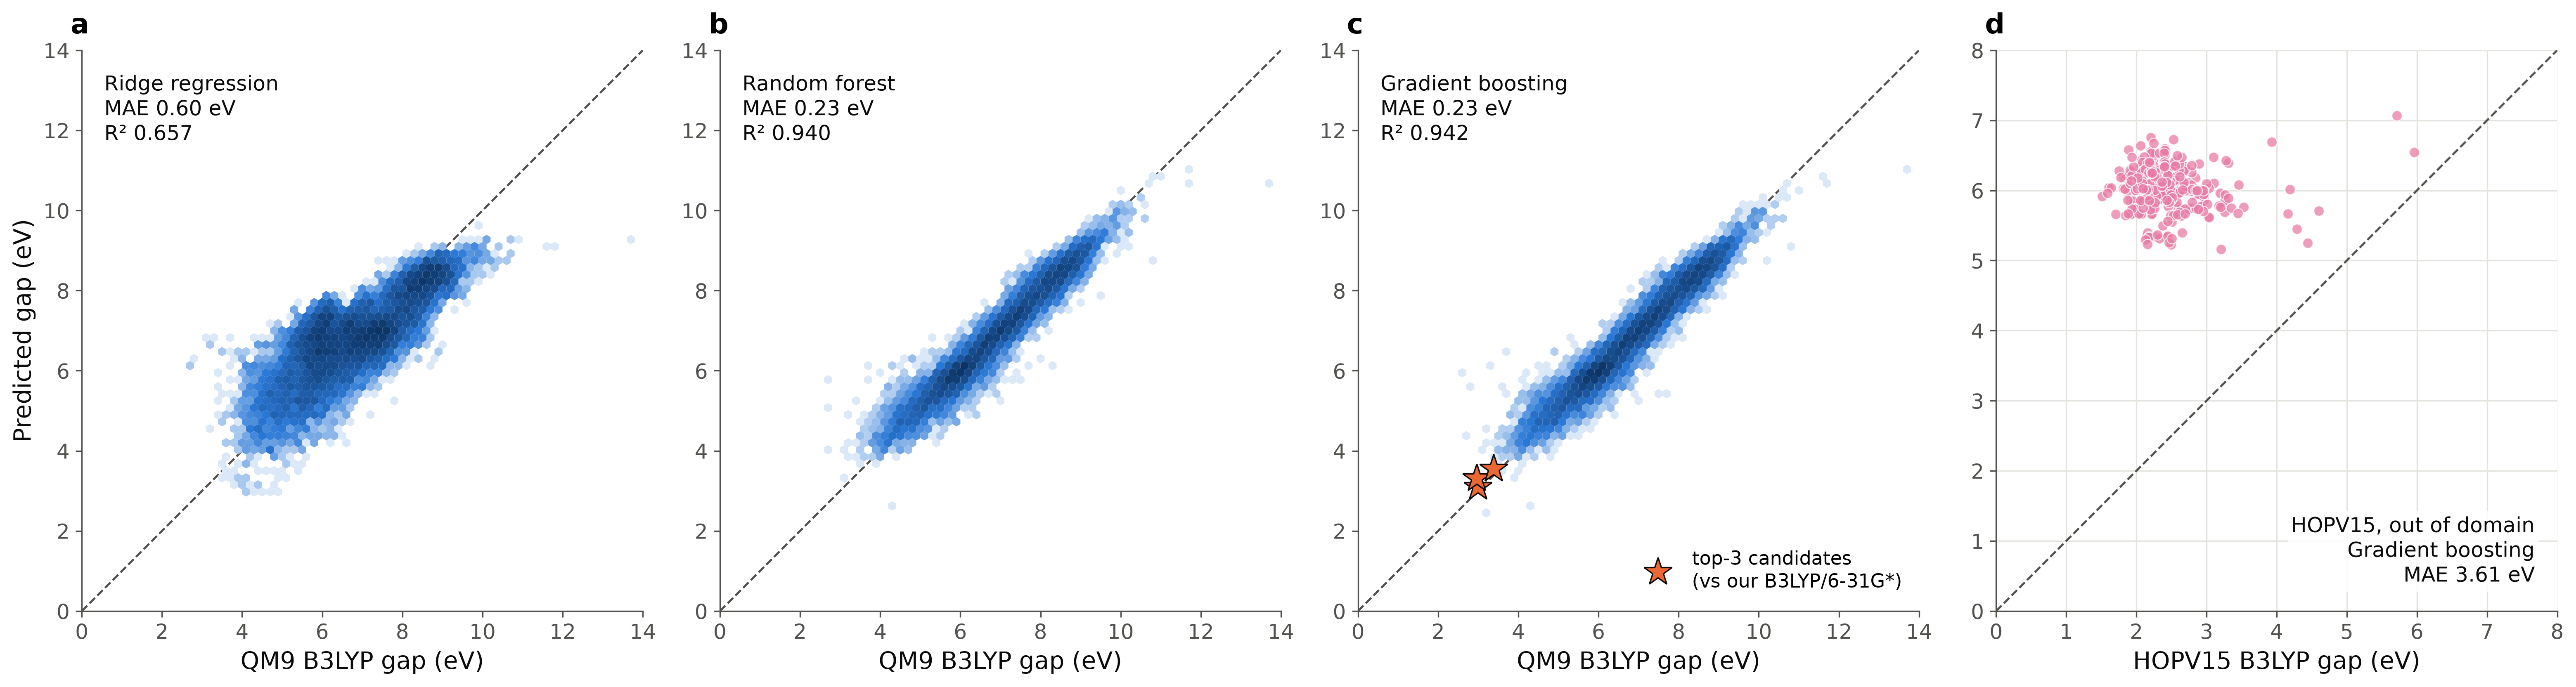

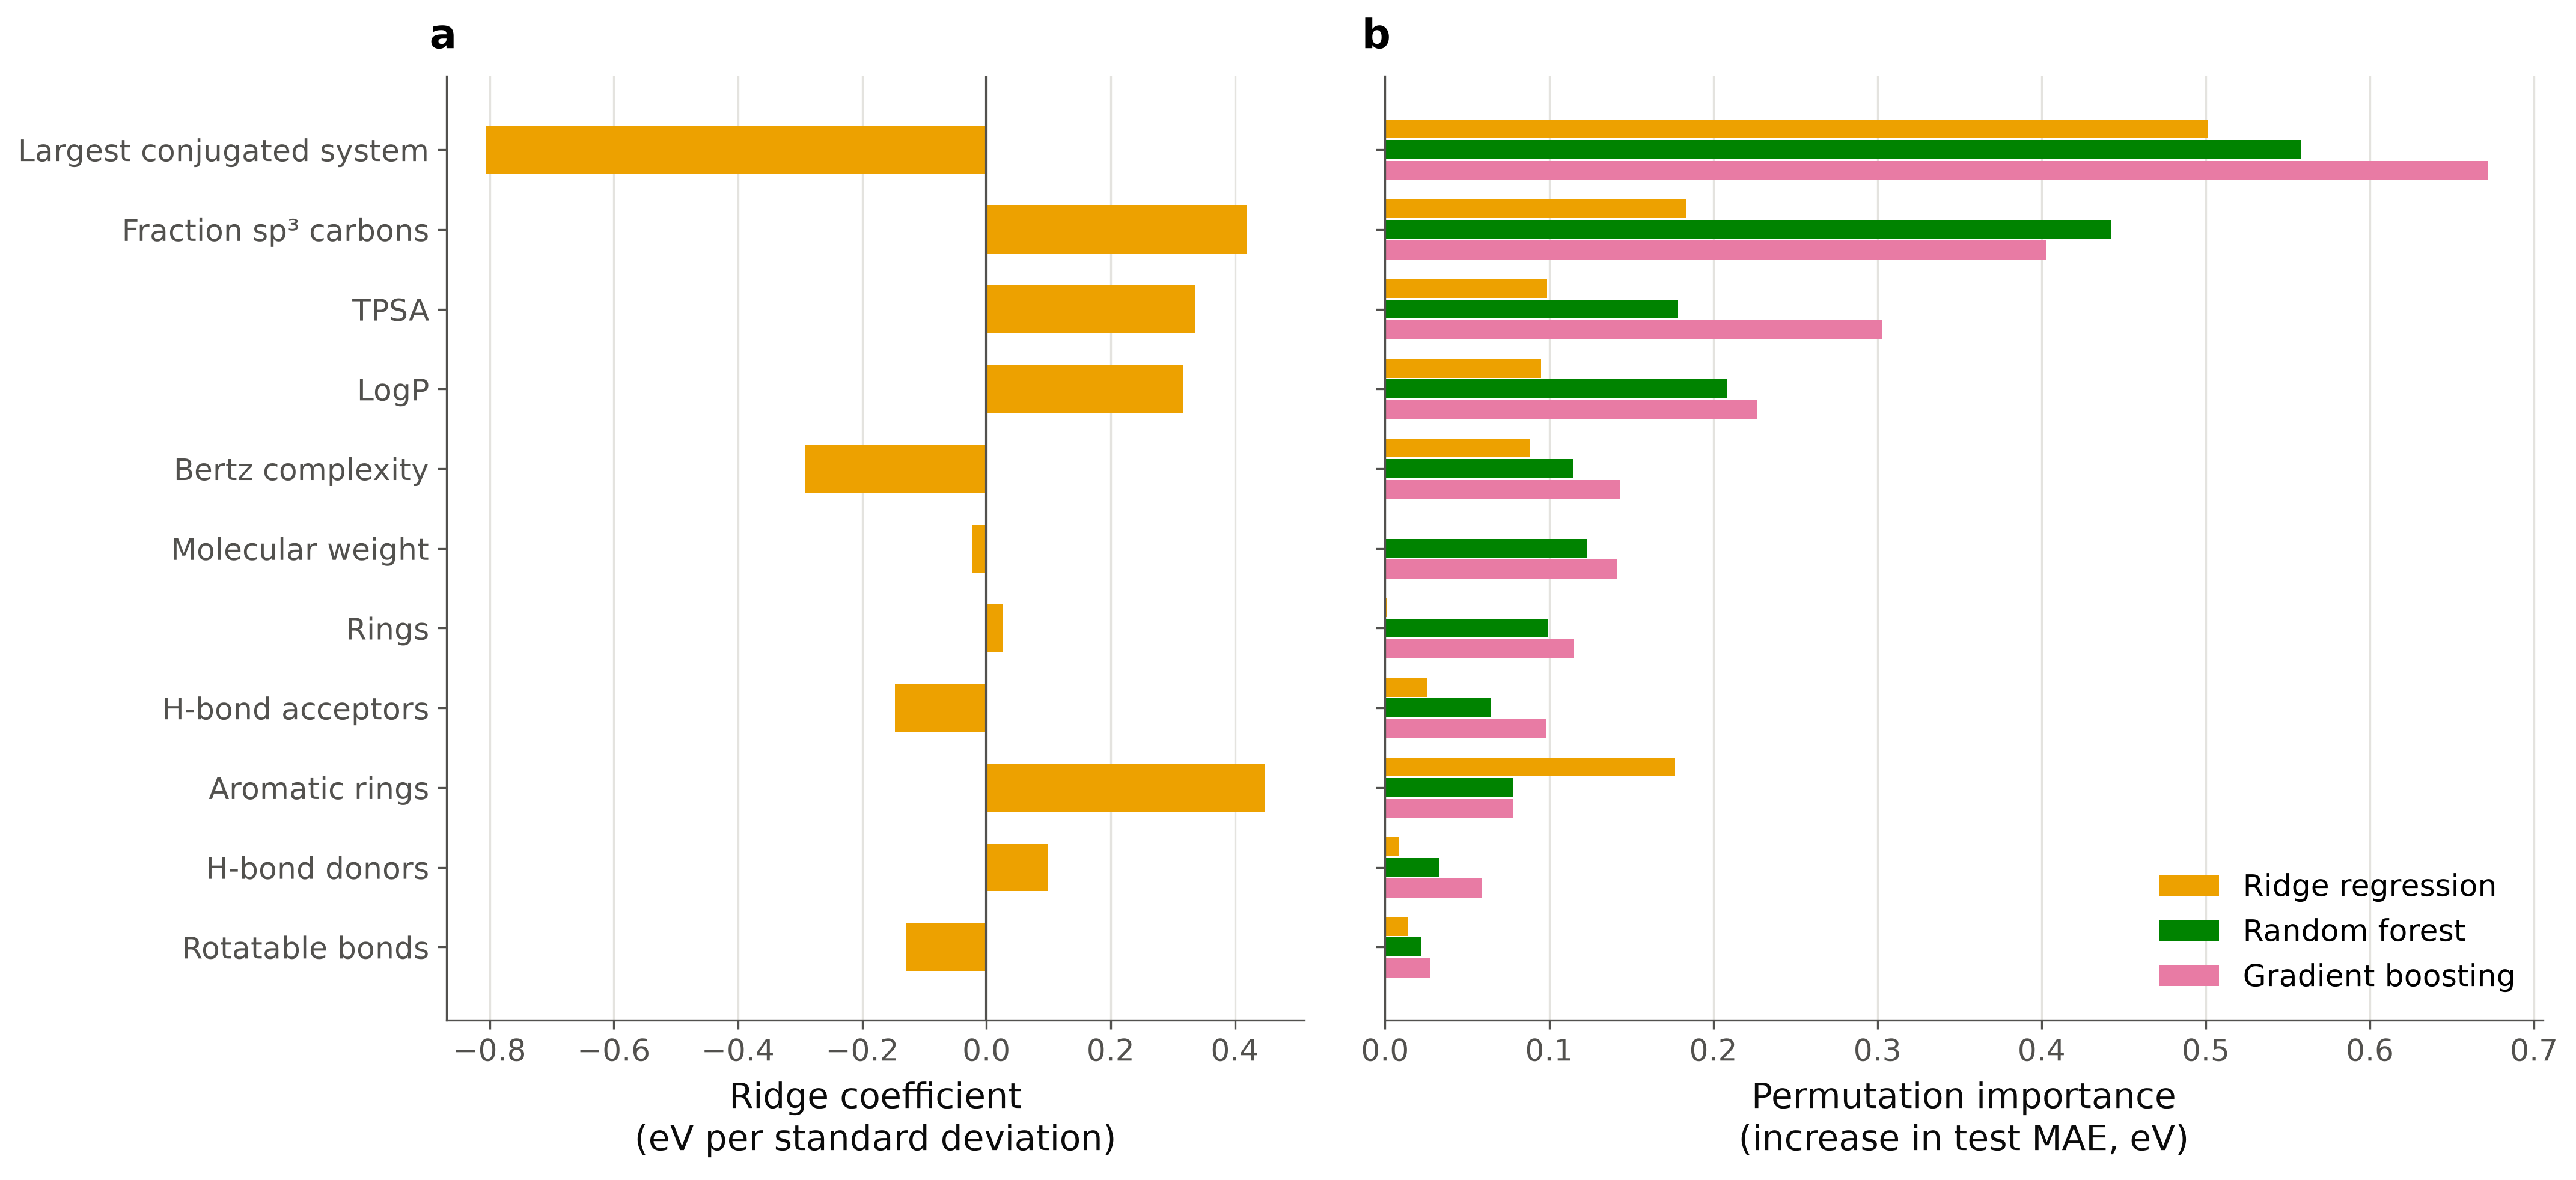

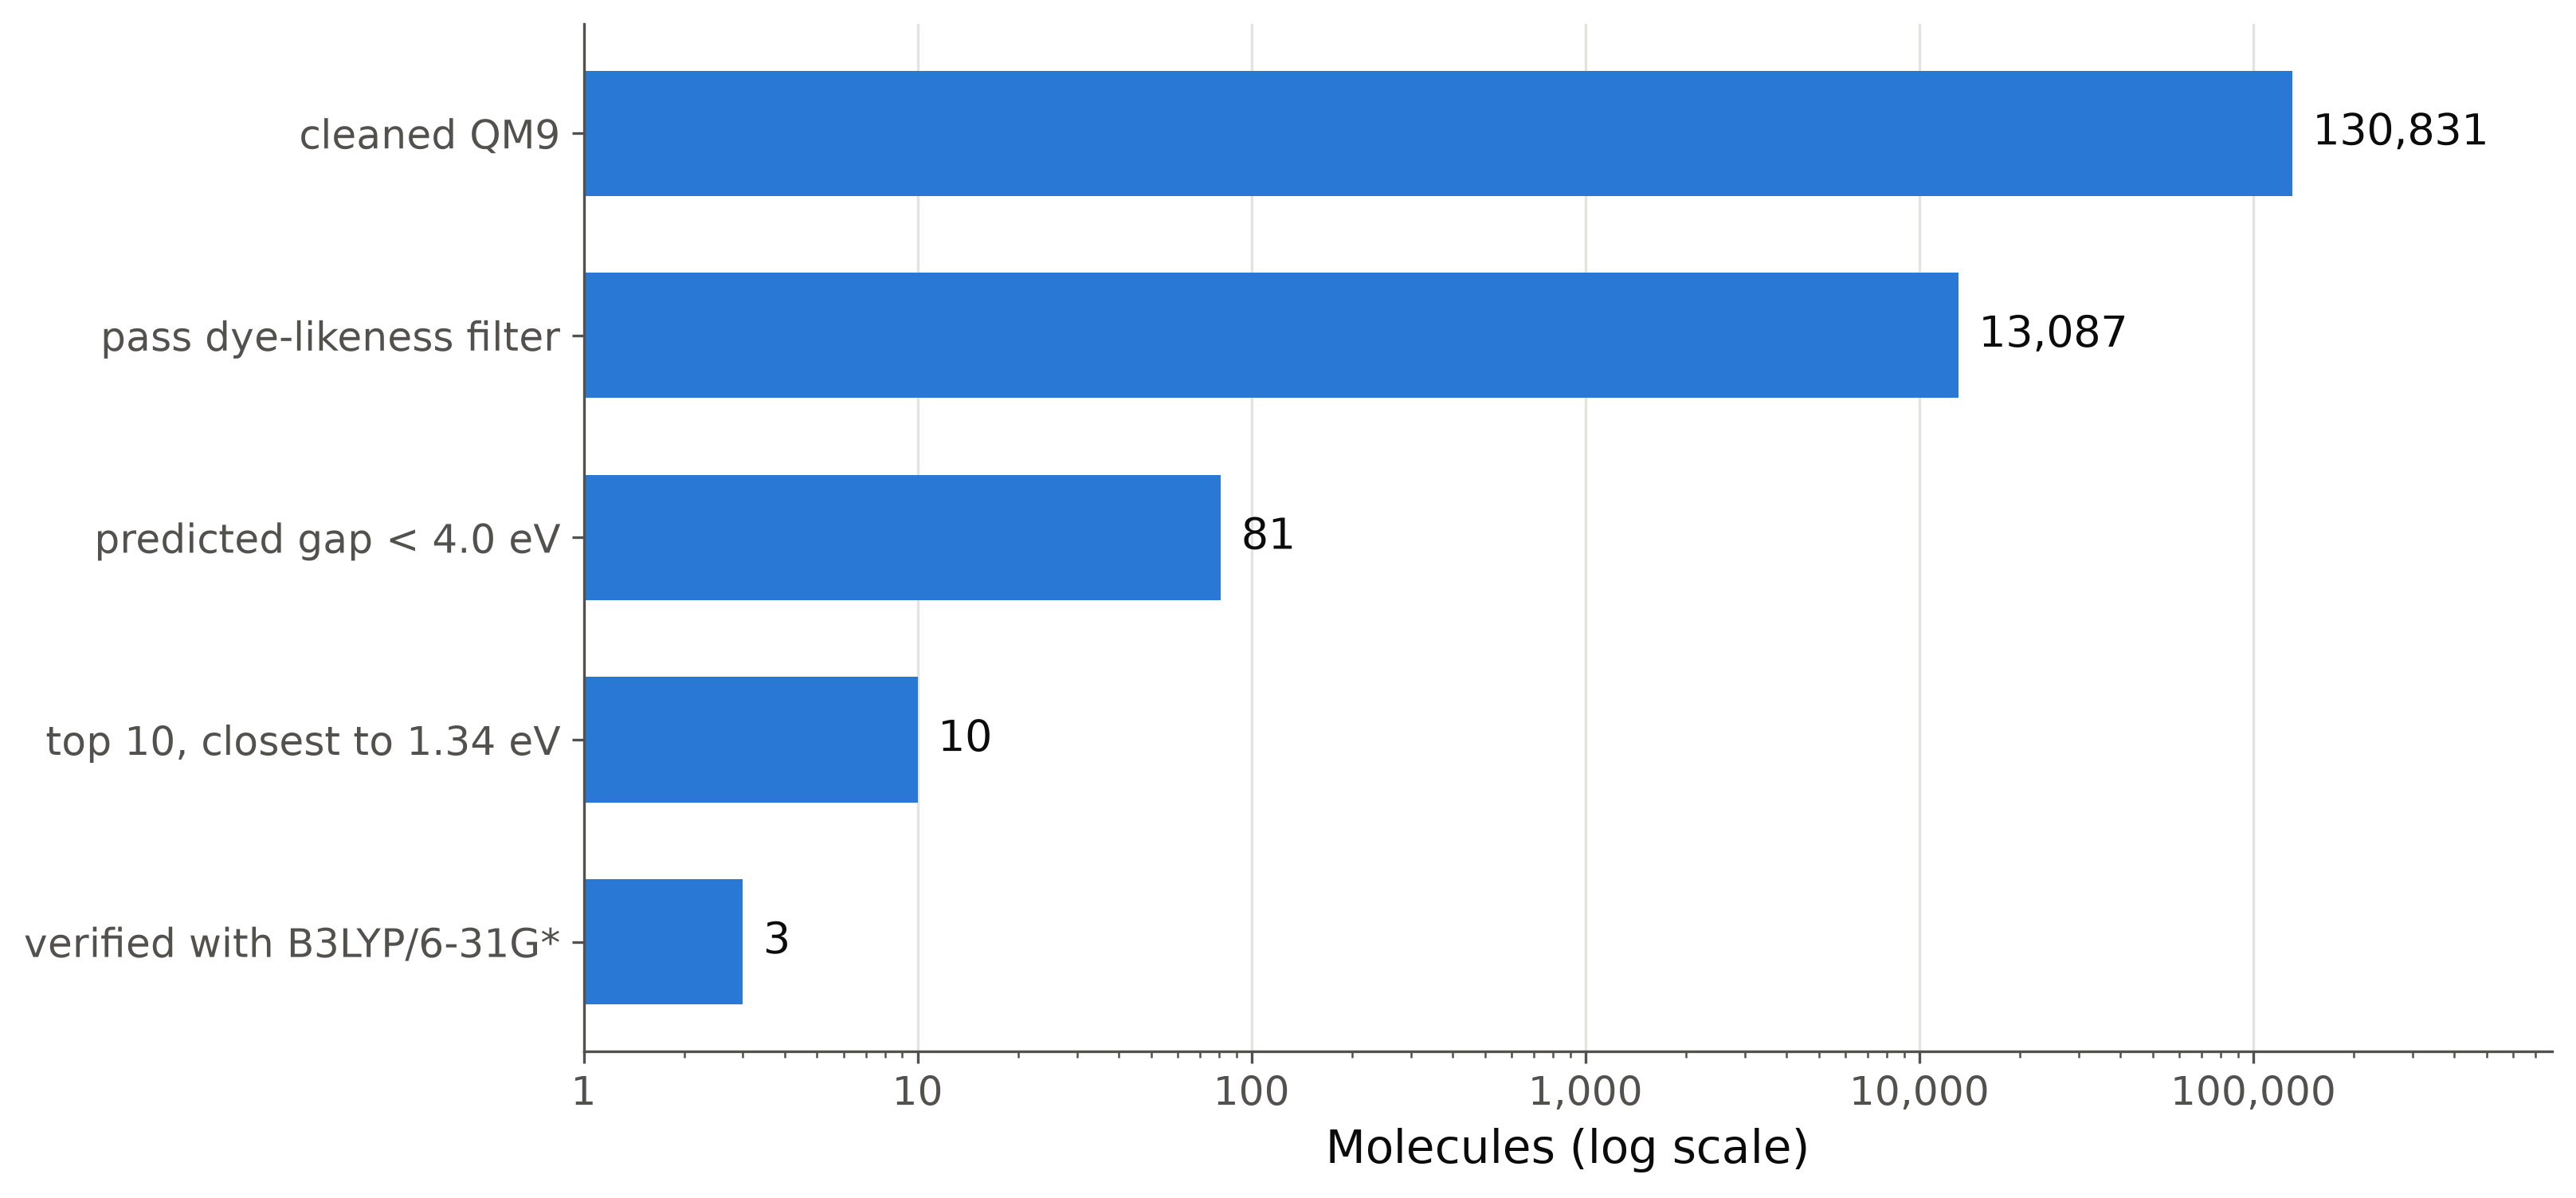

In [7]:
bundle, candidates = pipeline.run_model()
m = results_io.get_value("model")
print(f"{'model':<20}{'test MAE':>10}{'test RMSE':>11}{'test R2':>9}   hyperparameters")
for kind, values in m["metrics"].items():
    t = values["test"]
    print(f"{kind:<20}{t['MAE_eV']:>9.3f} {t['RMSE_eV']:>10.3f}{t['R2']:>9.3f}   {values['hyperparameters']}")
print(f"best model (by validation MAE): {m['best_model']}")
print()
print(f"{'rank':<5}{'SMILES':<26}{'predicted':>10}{'QM9 DFT':>9}{'our B3LYP':>11}  split")
for c in m["top_candidates"]:
    ours = f"{c['b3lyp_6_31Gs_gap_eV']:.2f}" if c["b3lyp_6_31Gs_gap_eV"] is not None else "-"
    print(f"{c['rank']:<5}{c['smiles']:<26}{c['predicted_gap_eV']:>10.2f}{c['qm9_gap_eV']:>9.2f}{ours:>11}  {c['split']}")
s = m["screening"]
print()
print(f"Closest predicted gap: {s['closest_predicted_gap_eV']:.2f} eV, "
      f"{s['closest_distance_from_target_eV']:.2f} eV away from the {s['target_gap_eV']:.2f} eV optimum")
print(f"Surrogate vs our B3LYP on the top 3: MAE {s['dft_check']['mean_absolute_error_predicted_vs_b3lyp_eV']:.2f} eV")
h = m["out_of_domain_hopv"]
print()
print(f"HOPV15 (out of domain, {h['molecules']} molecules, {h['heavy_atoms_range'][0]}-{h['heavy_atoms_range'][1]} heavy atoms):")
for kind, values in h["metrics"].items():
    print(f"  {kind:<20} MAE {values['MAE_eV']:6.2f} eV   predicted range {h['predicted_gap_range_eV'][kind][0]:.2f}"
          f" to {h['predicted_gap_range_eV'][kind][1]:.2f} eV")
print(f"  HOPV15 reference gaps span {h['reference_gap_range_eV'][0]:.2f} to {h['reference_gap_range_eV'][1]:.2f} eV")
show("fig11_parity", 980)
show("fig12_feature_importance", 900)
show("fig13_screening_funnel", 720)

## Validation
Every check recorded during the run, and a NaN scan of everything written to `results.json`. If any check fails,
the cell below raises an error, so a failure cannot slip by unnoticed.

In [8]:
bad_paths = results_io.find_nans(results_io.load_results())
results_io.record_check("no NaN or infinity anywhere in results.json", 0, len(bad_paths), len(bad_paths) == 0)

checks = results_io.load_results()["checks"]
failed = [check for check in checks if not check["passed"]]
for check in checks:
    print(("PASS  " if check["passed"] else "FAIL  ") + check["name"])
print()
print(f"{len(checks) - len(failed)}/{len(checks)} checks passed")
if failed:
    raise AssertionError("FAILED CHECKS: " + "; ".join(check["name"] for check in failed))

[PASS] no NaN or infinity anywhere in results.json: expected 0, got 0
PASS  all cleaned QM9 rows sanitise in RDKit
PASS  cleaned QM9 row count is roughly 130k (120k-134k)
PASS  HOPV15 parsed molecule count equals 350
PASS  QM9 molecules have at most 9 heavy atoms
PASS  SQ optimum gap within 0.05 eV of 1.34 eV
PASS  SQ optimum efficiency within 1 point of 33.7 %
PASS  integrated AM1.5G irradiance within 1 % of 1000 W/m^2
PASS  AM1.5G SQ curve shows the known secondary peak near 1.15 eV (H2O band)
PASS  global SQ maximum beats the 1.15 eV secondary peak
PASS  J_sc at optimum within 1 mA/cm^2 of 35.0 (Ruhle 2016)
PASS  HF gap > B3LYP gap for every molecule
PASS  HF gap decreases monotonically along the thiophene ladder
PASS  HF gap: biphenyl < benzene
PASS  B3LYP gap decreases monotonically along the thiophene ladder
PASS  B3LYP gap: biphenyl < benzene
PASS  B3LYP is closer to the experimental optical gap than HF
PASS  HF overestimates the experimental optical gap by more than 1 eV
PASS  